In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')


/kaggle/input/datasets/harshinikanala/lfs-files/fusion_best.pt
/kaggle/input/datasets/harshinikanala/lfs-files/weapon_best.pt
/kaggle/input/datasets/harshinikanala/main-repo/Violence-predictor-capstone-main/voilence_detection.py
/kaggle/input/datasets/harshinikanala/main-repo/Violence-predictor-capstone-main/desc.txt
/kaggle/input/datasets/harshinikanala/main-repo/Violence-predictor-capstone-main/.gitattributes
/kaggle/input/datasets/harshinikanala/main-repo/Violence-predictor-capstone-main/claude.md
/kaggle/input/datasets/harshinikanala/main-repo/Violence-predictor-capstone-main/violence-app/Dockerfile
/kaggle/input/datasets/harshinikanala/main-repo/Violence-predictor-capstone-main/violence-app/.gitignore
/kaggle/input/datasets/harshinikanala/main-repo/Violence-predictor-capstone-main/violence-app/README.md
/kaggle/input/datasets/harshinikanala/main-repo/Violence-predictor-capstone-main/violence-app/app.py
/kaggle/input/datasets/harshinikanala/main-repo/Violence-predictor-capstone-mai

In [10]:
import os
import cv2
import math
import random
import numpy as np
import pandas as pd

from pathlib import Path
from tqdm.auto import tqdm

TRAIN_ROOT = Path(
    "/kaggle/input/datasets/bypktt/xd-violence/train"
)

TEST_ROOT = Path(
    "/kaggle/input/datasets/bypktt/xd-violence/test"
)

print("Train:", TRAIN_ROOT)
print("Test :", TEST_ROOT)

print("\nTrain exists:", TRAIN_ROOT.exists())
print("Test exists :", TEST_ROOT.exists())

Train: /kaggle/input/datasets/bypktt/xd-violence/train
Test : /kaggle/input/datasets/bypktt/xd-violence/test

Train exists: True
Test exists : True


In [11]:
ALL_CLASSES = [
    "Abuse",
    "CarAccident",
    "Explosion",
    "Fighting",
    "Normal",
    "Riot",
    "Shooting"
]

USED_CLASSES = [
    "CarAccident",
    "Explosion",
    "Fighting",
    "Normal",
    "Riot",
    "Shooting"
]

VIOLENCE_CLASSES = [
    "CarAccident",
    "Explosion",
    "Fighting",
    "Riot",
    "Shooting"
]

LABEL_MAP = {
    "Normal": 0,
    "CarAccident": 1,
    "Explosion": 1,
    "Fighting": 1,
    "Riot": 1,
    "Shooting": 1
}

print("Excluded:", "Abuse")
print("Used classes:", USED_CLASSES)
print("Violence classes:", VIOLENCE_CLASSES)

Excluded: Abuse
Used classes: ['CarAccident', 'Explosion', 'Fighting', 'Normal', 'Riot', 'Shooting']
Violence classes: ['CarAccident', 'Explosion', 'Fighting', 'Riot', 'Shooting']


In [12]:
VIDEO_EXTENSIONS = {
    ".mp4",
    ".avi",
    ".mov",
    ".mkv",
    ".webm"
}


def collect_videos(root, split):

    records = []

    for class_name in USED_CLASSES:

        class_dir = root / class_name

        if not class_dir.exists():
            print(
                f"WARNING: missing directory: {class_dir}"
            )
            continue

        for video_path in class_dir.rglob("*"):

            if (
                video_path.is_file()
                and video_path.suffix.lower()
                in VIDEO_EXTENSIONS
            ):

                records.append({
                    "path": str(video_path),
                    "split": split,
                    "class": class_name,
                    "label": LABEL_MAP[class_name]
                })

    return records


train_records = collect_videos(
    TRAIN_ROOT,
    "train"
)

test_records = collect_videos(
    TEST_ROOT,
    "test"
)

records = train_records + test_records

df = pd.DataFrame(records)

print("Total videos:", len(df))
print("\nSplit:")
print(df["split"].value_counts())

print("\nClass:")
print(df["class"].value_counts())

print("\nBinary label:")
print(df["label"].value_counts())

Total videos: 4426

Split:
split
train    3680
test      746
Name: count, dtype: int64

Class:
class
Normal         2349
Fighting        484
Riot            473
CarAccident     468
Explosion       358
Shooting        294
Name: count, dtype: int64

Binary label:
label
0    2349
1    2077
Name: count, dtype: int64


In [14]:
def get_video_metadata(path):

    cap = cv2.VideoCapture(path)

    if not cap.isOpened():
        return np.nan, np.nan, np.nan

    fps = cap.get(
        cv2.CAP_PROP_FPS
    )

    frame_count = cap.get(
        cv2.CAP_PROP_FRAME_COUNT
    )

    duration = np.nan

    if (
        fps is not None
        and fps > 0
        and frame_count is not None
        and frame_count > 0
    ):
        duration = frame_count / fps

    cap.release()

    return duration, fps, frame_count


metadata = []

for path in tqdm(
    df["path"],
    desc="Reading video metadata"
):

    duration, fps, frame_count = (
        get_video_metadata(path)
    )

    metadata.append(
        (
            duration,
            fps,
            frame_count
        )
    )


df[
    [
        "duration",
        "fps",
        "frame_count"
    ]
] = pd.DataFrame(
    metadata,
    index=df.index
)

Reading video metadata:   0%|          | 0/4426 [00:00<?, ?it/s]

[mov,mp4,m4a,3gp,3g2,mj2 @ 0x27745740] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x27745740] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x27745740] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x27745740] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x273e05c0] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x27745740] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x27758f40] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x273e05c0] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x27770a40] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x27596880] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x273e05c0] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x273e05c0] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x273e05c0] Referenced QT chapter track not found

In [15]:
before = len(df)

bad_metadata = (
    df["duration"].isna()
    | (df["duration"] <= 0)
    | df["fps"].isna()
    | (df["fps"] <= 0)
    | df["frame_count"].isna()
    | (df["frame_count"] <= 0)
)

print(
    "Videos with invalid metadata:",
    bad_metadata.sum()
)

if bad_metadata.sum() > 0:

    print(
        df.loc[
            bad_metadata,
            [
                "split",
                "class",
                "path"
            ]
        ].to_string(index=False)
    )

df = (
    df.loc[~bad_metadata]
    .reset_index(drop=True)
)

print(
    "\nVideos remaining:",
    len(df)
)

Videos with invalid metadata: 1
split  class                                                                                        path
train Normal /kaggle/input/datasets/bypktt/xd-violence/train/Normal/Normal_v=8cTqh9tMz_I___1_label_A.mp4

Videos remaining: 4425


In [18]:
WINDOW_SEC = 4.0
STRIDE_SEC = 2.0
FRAMES_PER_WINDOW = 16

IMG_SIZE = 112

In [20]:
def calculate_num_windows(duration):

    if (
        pd.isna(duration)
        or duration <= 0
    ):
        return 0

    if duration <= WINDOW_SEC:
        return 1

    return (
        int(
            np.floor(
                (duration - WINDOW_SEC)
                / STRIDE_SEC
            )
        )
        + 1
    )


df["num_windows"] = (
    df["duration"]
    .apply(calculate_num_windows)
)

print(
    df["num_windows"].describe(
        percentiles=[
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
)

print("\nTotal windows:")
print(
    int(df["num_windows"].sum())
)

print("\nWindows by split:")
print(
    df.groupby("split")["num_windows"]
    .sum()
)

count    4425.000000
mean       83.119774
std       164.688949
min         1.000000
25%        29.000000
50%        52.000000
75%        89.000000
90%       160.000000
95%       209.800000
99%       573.360000
max      5407.000000
Name: num_windows, dtype: float64

Total windows:
367805

Windows by split:
split
test      45547
train    322258
Name: num_windows, dtype: int64


In [21]:
MANIFEST_PATH = (
    "/kaggle/working/"
    "xdviolence_clean_manifest.csv"
)

df.to_csv(
    MANIFEST_PATH,
    index=False
)

print(
    "Saved:",
    MANIFEST_PATH
)

Saved: /kaggle/working/xdviolence_clean_manifest.csv


In [22]:
print("=" * 70)
print("FINAL DATASET")
print("=" * 70)

print("\nVideos:")
print(
    df.groupby(
        ["split", "class"]
    ).size()
)

print("\nBinary labels:")
print(
    df.groupby(
        ["split", "label"]
    ).size()
)

print("\nDuration:")
print(
    df["duration"].describe()
)

print("\nWindows:")
print(
    df["num_windows"].describe()
)

FINAL DATASET

Videos:
split  class      
test   CarAccident      93
       Explosion        85
       Fighting        107
       Normal          300
       Riot             99
       Shooting         62
train  CarAccident     375
       Explosion       273
       Fighting        377
       Normal         2048
       Riot            374
       Shooting        232
dtype: int64

Binary labels:
split  label
test   0         300
       1         446
train  0        2048
       1        1631
dtype: int64

Duration:
count     4425.000000
mean       168.896478
std        329.388223
min          1.416667
25%         60.000000
50%        107.083333
75%        180.125000
max      10816.208333
Name: duration, dtype: float64

Windows:
count    4425.000000
mean       83.119774
std       164.688949
min         1.000000
25%        29.000000
50%        52.000000
75%        89.000000
max      5407.000000
Name: num_windows, dtype: float64


In [23]:
def read_window_frames(
    video_path,
    start_sec,
    window_sec=WINDOW_SEC,
    num_frames=FRAMES_PER_WINDOW,
    img_size=IMG_SIZE
):

    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        raise RuntimeError(
            f"Could not open video: {video_path}"
        )

    fps = cap.get(
        cv2.CAP_PROP_FPS
    )

    if fps <= 0:
        cap.release()
        raise RuntimeError(
            f"Invalid FPS: {video_path}"
        )

    start_frame = int(
        start_sec * fps
    )

    end_frame = int(
        (start_sec + window_sec)
        * fps
    )

    frame_indices = np.linspace(
        start_frame,
        max(start_frame, end_frame - 1),
        num_frames
    ).astype(int)

    frames = []

    for frame_idx in frame_indices:

        cap.set(
            cv2.CAP_PROP_POS_FRAMES,
            int(frame_idx)
        )

        ret, frame = cap.read()

        if not ret:
            continue

        frame = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2RGB
        )

        frame = cv2.resize(
            frame,
            (img_size, img_size)
        )

        frames.append(frame)

    cap.release()

    # Handle missing frames
    if len(frames) == 0:
        raise RuntimeError(
            f"No frames read: {video_path}"
        )

    while len(frames) < num_frames:
        frames.append(
            frames[-1].copy()
        )

    frames = frames[:num_frames]

    return np.stack(frames)

In [24]:
test_row = df.iloc[0]

frames = read_window_frames(
    test_row["path"],
    start_sec=0
)

print(
    "Frames shape:",
    frames.shape
)

print(
    "Expected:",
    (
        FRAMES_PER_WINDOW,
        IMG_SIZE,
        IMG_SIZE,
        3
    )
)

Frames shape: (16, 112, 112, 3)
Expected: (16, 112, 112, 3)


In [25]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

import torchvision
from torchvision import models, transforms

print("PyTorch:", torch.__version__)

print(
    "GPU count:",
    torch.cuda.device_count()
)

for i in range(torch.cuda.device_count()):
    print(
        i,
        torch.cuda.get_device_name(i)
    )

PyTorch: 2.10.0+cu128
GPU count: 2
0 Tesla T4
1 Tesla T4


In [30]:
weights = (
    models.ResNet18_Weights.DEFAULT
)

preprocess = (
    weights.transforms()
)

In [58]:
class ViolenceWindowDataset(Dataset):

    def __init__(
        self,
        dataframe,
        max_windows_per_video=None,
        training=True
    ):

        self.df = (
            dataframe
            .reset_index(drop=True)
            .copy()
        )

        self.training = training

        self.samples = []

        for video_idx, row in self.df.iterrows():

            n_windows = int(
                row["num_windows"]
            )

            if n_windows <= 0:
                continue

            # ------------------------------------------------
            # Training: limit windows from extremely long videos
            # ------------------------------------------------

            if (
                training
                and max_windows_per_video is not None
                and n_windows > max_windows_per_video
            ):

                selected = np.linspace(
                    0,
                    n_windows - 1,
                    max_windows_per_video
                ).astype(int)

            else:

                selected = np.arange(
                    n_windows
                )

            for window_idx in selected:

                start_sec = (
                    window_idx
                    * STRIDE_SEC
                )

                self.samples.append(
                    (
                        video_idx,
                        window_idx,
                        start_sec
                    )
                )

        print(
            "Window samples:",
            len(self.samples)
        )

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):

        video_idx, window_idx, start_sec = (
            self.samples[idx]
        )

        row = self.df.iloc[
            video_idx
        ]

        frames = read_window_frames(
            row["path"],
            start_sec
        )

        # Convert:
        # T,H,W,C -> T,C,H,W

        frames = torch.from_numpy(
            frames
        ).float() / 255.0

        frames = frames.permute(
            0, 3, 1, 2
        )

        # Normalize each frame
        normalized_frames = []

        for frame in frames:

            normalized_frames.append(
                preprocess(
                    frame
                )
            )

        frames = torch.stack(
            normalized_frames
        )

        label = torch.tensor(
            row["label"],
            dtype=torch.float32
        )

        return {
            "frames": frames,
            "label": label,
            "video_idx": video_idx,
            "window_idx": window_idx,
            "start_sec": start_sec
        }

In [59]:
train_df = df[
    df["split"] == "train"
].reset_index(drop=True)

test_df = df[
    df["split"] == "test"
].reset_index(drop=True)

print(
    "Train videos:",
    len(train_df)
)

print(
    "Test videos:",
    len(test_df)
)

Train videos: 3679
Test videos: 746


In [60]:
train_dataset = ViolenceWindowDataset(
    train_df,
    max_windows_per_video=64,
    training=True
)

sample = train_dataset[0]

print(
    "Frames:",
    sample["frames"].shape
)

print(
    "Label:",
    sample["label"]
)

print(
    "Window:",
    sample["window_idx"]
)

print(
    "Start:",
    sample["start_sec"]
)

Window samples: 170477
Frames: torch.Size([16, 3, 224, 224])
Label: tensor(1.)
Window: 0
Start: 0.0


In [61]:
import torch
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights


class ViolenceVideoModel(nn.Module):
    def __init__(self, hidden_size=256, num_classes=1):
        super().__init__()

        # Pretrained spatial feature extractor
        backbone = resnet18(weights=ResNet18_Weights.DEFAULT)

        # Remove final classification layer
        self.cnn = nn.Sequential(
            *list(backbone.children())[:-1]
        )

        self.feature_dim = 512

        # Temporal modeling
        self.gru = nn.GRU(
            input_size=self.feature_dim,
            hidden_size=hidden_size,
            num_layers=2,
            batch_first=True,
            dropout=0.2
        )

        # Binary classifier
        self.classifier = nn.Sequential(
            nn.Linear(hidden_size, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        # x: [B, T, C, H, W]

        B, T, C, H, W = x.shape

        # Process all frames through CNN
        x = x.view(B * T, C, H, W)

        features = self.cnn(x)

        # [B*T, 512, 1, 1] -> [B*T, 512]
        features = features.flatten(1)

        # Restore temporal dimension
        features = features.view(B, T, self.feature_dim)

        # Temporal modeling
        output, _ = self.gru(features)

        # Use final timestep
        x = output[:, -1, :]

        # Binary classification
        logits = self.classifier(x)

        return logits.squeeze(1)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = ViolenceVideoModel()

print(model)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 133MB/s] 


ViolenceVideoModel(
  (cnn): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (4): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stat

In [62]:
from torch.utils.data import DataLoader

test_loader = DataLoader(
    train_dataset,
    batch_size=2,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

batch = next(iter(test_loader))

print("Frames shape:", batch["frames"].shape)
print("Labels shape:", batch["label"].shape)
print("Labels:", batch["label"])

Frames shape: torch.Size([2, 16, 3, 224, 224])
Labels shape: torch.Size([2])
Labels: tensor([1., 1.])


In [63]:
model = model.to(device)

frames = batch["frames"].to(device)

with torch.no_grad():
    logits = model(frames)

print("Input:", frames.shape)
print("Output:", logits.shape)
print("Logits:", logits)

Input: torch.Size([2, 16, 3, 224, 224])
Output: torch.Size([2])
Logits: tensor([-0.1648, -0.2580], device='cuda:0')


In [64]:
import torch
import torch.nn as nn

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scaler = torch.amp.GradScaler("cuda")

print("Criterion:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("AMP enabled")

Criterion: BCEWithLogitsLoss()
Optimizer: AdamW
AMP enabled


In [75]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

print("Training windows:", len(train_dataset))
print("Batches per epoch:", len(train_loader))

Training windows: 170477
Batches per epoch: 42620


In [76]:
batch = next(iter(train_loader))

print("Frames:", batch["frames"].shape)
print("Labels:", batch["label"].shape)
print("Labels:", batch["label"])

Frames: torch.Size([4, 16, 3, 224, 224])
Labels: torch.Size([4])
Labels: tensor([0., 0., 0., 0.])


In [78]:
frames = batch["frames"].to(device, non_blocking=True)
labels = batch["label"].float().to(device, non_blocking=True)

print("GPU frames:", frames.shape)
print("GPU labels:", labels.shape)

GPU frames: torch.Size([4, 16, 3, 224, 224])
GPU labels: torch.Size([4])


In [79]:
import time
import torch
import numpy as np
import pandas as pd

model.train()

MAX_BATCHES = 500

records = []

running_loss = 0.0
correct = 0
total = 0

start_time = time.time()

for batch_idx, batch in enumerate(train_loader):

    if batch_idx >= MAX_BATCHES:
        break

    batch_start = time.time()

    frames = batch["frames"].to(device, non_blocking=True)
    labels = batch["label"].float().to(device, non_blocking=True)

    optimizer.zero_grad(set_to_none=True)

    with torch.amp.autocast("cuda"):
        logits = model(frames)
        loss = criterion(logits, labels)

    scaler.scale(loss).backward()
    scaler.step(optimizer)
    scaler.update()

    running_loss += loss.item() * labels.size(0)

    predictions = (torch.sigmoid(logits) >= 0.5).float()

    correct += (predictions == labels).sum().item()
    total += labels.size(0)

    # Timing
    batch_time = time.time() - batch_start
    elapsed = time.time() - start_time

    avg_batch_time = elapsed / (batch_idx + 1)

    remaining_batches = MAX_BATCHES - (batch_idx + 1)
    eta_seconds = remaining_batches * avg_batch_time

    # GPU memory
    gpu_memory_gb = (
        torch.cuda.memory_allocated(device) / (1024 ** 3)
    )

    records.append({
        "batch": batch_idx + 1,
        "loss": loss.item(),
        "running_accuracy": correct / total,
        "batch_time_sec": batch_time,
        "avg_batch_time_sec": avg_batch_time,
        "elapsed_min": elapsed / 60,
        "ETA_min": eta_seconds / 60,
        "GPU_memory_GB": gpu_memory_gb
    })

    # Display every 25 batches
    if (batch_idx + 1) % 25 == 0:

        progress_df = pd.DataFrame(records)

        display(
            progress_df.tail(5)
        )

        print(
            f"\nProgress: {batch_idx + 1}/{MAX_BATCHES} "
            f"({100 * (batch_idx + 1) / MAX_BATCHES:.1f}%)"
        )

        print(
            f"Elapsed: {elapsed / 60:.2f} min | "
            f"ETA: {eta_seconds / 60:.2f} min | "
            f"Avg batch: {avg_batch_time:.2f} sec"
        )

        print(
            f"GPU memory: {gpu_memory_gb:.2f} GB"
        )


# Final DataFrame
timing_df = pd.DataFrame(records)

print("\n===== 500 BATCH TEST COMPLETE =====")

print(
    f"Total time: "
    f"{timing_df['elapsed_min'].iloc[-1]:.2f} minutes"
)

print(
    f"Average batch time: "
    f"{timing_df['batch_time_sec'].mean():.2f} sec"
)

print(
    f"Average loss: "
    f"{running_loss / total:.4f}"
)

print(
    f"Accuracy: "
    f"{correct / total:.4f}"
)

print(
    f"GPU memory: "
    f"{timing_df['GPU_memory_GB'].iloc[-1]:.2f} GB"
)

timing_df.tail(10)

[mov,mp4,m4a,3gp,3g2,mj2 @ 0x5e5c6a40] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x5e54ba80] Referenced QT chapter track not found


,batch,loss,running_accuracy,batch_time_sec,avg_batch_time_sec,elapsed_min,ETA_min,GPU_memory_GB
20,21,0.582653,0.654762,0.120561,3.874122,1.355943,30.928406,0.239831
21,22,0.518804,0.670455,0.114985,3.749912,1.374968,29.874298,0.239831
22,23,0.769872,0.663043,0.120412,3.768221,1.444485,29.957355,0.239831
23,24,0.526324,0.677083,0.120432,3.924237,1.569695,31.132279,0.239831
24,25,0.780294,0.660000,0.120473,3.772112,1.571713,29.862556,0.239831



Progress: 25/500 (5.0%)
Elapsed: 1.57 min | ETA: 29.86 min | Avg batch: 3.77 sec
GPU memory: 0.24 GB


,batch,loss,running_accuracy,batch_time_sec,avg_batch_time_sec,elapsed_min,ETA_min,GPU_memory_GB
45,46,0.458569,0.684783,0.118916,3.502665,2.685377,26.503500,0.239831
46,47,0.401602,0.691489,0.111456,3.430524,2.687244,25.900455,0.239831
47,48,0.900380,0.687500,0.120400,3.545362,2.836290,26.708395,0.239831
48,49,0.933067,0.678571,0.120231,3.475472,2.838302,26.123968,0.239831
49,50,0.505403,0.680000,0.120286,3.529559,2.941300,26.471696,0.239831



Progress: 50/500 (10.0%)
Elapsed: 2.94 min | ETA: 26.47 min | Avg batch: 3.53 sec
GPU memory: 0.24 GB


...


Progress: 475/500 (95.0%)
Elapsed: 26.83 min | ETA: 1.41 min | Avg batch: 3.39 sec
GPU memory: 0.24 GB


[mov,mp4,m4a,3gp,3g2,mj2 @ 0x5e5c6a40] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x5e5e59c0] Referenced QT chapter track not found


,batch,loss,running_accuracy,batch_time_sec,avg_batch_time_sec,elapsed_min,ETA_min,GPU_memory_GB
495,496,0.912332,0.671371,0.101068,3.379668,27.938588,0.225311,0.239831
496,497,0.390912,0.672032,0.119608,3.389713,28.078122,0.169486,0.239831
497,498,0.446691,0.672189,0.100537,3.383110,28.079809,0.112770,0.239831
498,499,0.791933,0.671844,0.120283,3.388844,28.183885,0.056481,0.239831
499,500,0.368218,0.672500,0.107367,3.382282,28.185687,0.000000,0.239831



Progress: 500/500 (100.0%)
Elapsed: 28.19 min | ETA: 0.00 min | Avg batch: 3.38 sec
GPU memory: 0.24 GB

===== 500 BATCH TEST COMPLETE =====
Total time: 28.19 minutes
Average batch time: 0.12 sec
Average loss: 0.6057
Accuracy: 0.6725
GPU memory: 0.24 GB


,batch,loss,running_accuracy,batch_time_sec,avg_batch_time_sec,elapsed_min,ETA_min,GPU_memory_GB
490,491,0.348069,0.671589,0.120092,3.390103,27.742345,0.508515,0.239831
491,492,0.416549,0.671748,0.113940,3.383445,27.744253,0.451126,0.239831
492,493,0.428489,0.671907,0.120092,3.387892,27.837176,0.395254,0.239831
493,494,0.759981,0.671559,0.096612,3.381230,27.838797,0.338123,0.239831
494,495,0.529833,0.671717,0.120229,3.386290,27.936892,0.282191,0.239831
495,496,0.912332,0.671371,0.101068,3.379668,27.938588,0.225311,0.239831
496,497,0.390912,0.672032,0.119608,3.389713,28.078122,0.169486,0.239831
497,498,0.446691,0.672189,0.100537,3.383110,28.079809,0.112770,0.239831
498,499,0.791933,0.671844,0.120283,3.388844,28.183885,0.056481,0.239831
499,500,0.368218,0.672500,0.107367,3.382282,28.185687,0.000000,0.239831


In [80]:
print("Columns:")
print(train_df.columns.tolist())

print("\nNumber of videos:")
print(len(train_df))

print("\nClass distribution:")
print(train_df["class"].value_counts())

print("\nUnique values for each column:")
for col in train_df.columns:
    if train_df[col].dtype == "object":
        print(f"\n--- {col} ---")
        print(train_df[col].value_counts().head(30))

Columns:
['path', 'split', 'class', 'label', 'duration', 'fps', 'frame_count', 'num_windows']

Number of videos:
3679

Class distribution:
class
Normal         2048
Fighting        377
CarAccident     375
Riot            374
Explosion       273
Shooting        232
Name: count, dtype: int64

Unique values for each column:

--- path ---
path
/kaggle/input/datasets/bypktt/xd-violence/train/Shooting/Shooting_Tropa.de.Elite.2.2010___00-02-10_00-03-45_label_B2-0-0.mp4        1
/kaggle/input/datasets/bypktt/xd-violence/train/CarAccident/CarAccident_v=k7R_Qo-BiAw___00-06-10_00-07-19_label_B6-0-0.mp4          1
/kaggle/input/datasets/bypktt/xd-violence/train/CarAccident/CarAccident_v=vhACO_m5pH0___00-22-42_00-24-10_label_B6-0-0.mp4          1
/kaggle/input/datasets/bypktt/xd-violence/train/CarAccident/CarAccident_v=66F2bVUq_zk___00-00-00_00-00-51_label_B6-0-0.mp4          1
/kaggle/input/datasets/bypktt/xd-violence/train/CarAccident/CarAccident_Brick.Mansions.2014___00-40-15_00-40-55_label_B6-0

In [91]:
# ============================================================
# CLEAN SOURCE-LEVEL 70/15/15 SPLIT
# ============================================================

import numpy as np
import pandas as pd

RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

# Work with ALL clips
all_df = df.copy()

# Store source-level assignment
source_split = {}

classes = sorted(all_df["class"].unique())

for cls in classes:

    # All unique sources for this class
    sources = (
        all_df.loc[all_df["class"] == cls, "source_id"]
        .drop_duplicates()
        .values
    )

    # Shuffle reproducibly
    rng.shuffle(sources)

    n = len(sources)

    # 70 / 15 / 15
    n_train = int(n * 0.70)
    n_val = int(n * 0.15)

    train_sources = sources[:n_train]
    val_sources = sources[n_train:n_train + n_val]
    test_sources = sources[n_train + n_val:]

    for s in train_sources:
        source_split[s] = "train"

    for s in val_sources:
        source_split[s] = "val"

    for s in test_sources:
        source_split[s] = "test"


# Assign split based ONLY on source_id
all_df["model_split"] = all_df["source_id"].map(source_split)

# ============================================================
# CREATE FINAL DATAFRAMES
# ============================================================

model_train = all_df[
    all_df["model_split"] == "train"
].copy()

model_val = all_df[
    all_df["model_split"] == "val"
].copy()

model_test = all_df[
    all_df["model_split"] == "test"
].copy()


# ============================================================
# VERIFY NO SOURCE LEAKAGE
# ============================================================

train_sources = set(model_train["source_id"])
val_sources = set(model_val["source_id"])
test_sources = set(model_test["source_id"])

print("=" * 60)
print("SOURCE LEAKAGE CHECK")
print("=" * 60)

print("Train ∩ Val :", len(train_sources & val_sources))
print("Train ∩ Test:", len(train_sources & test_sources))
print("Val ∩ Test  :", len(val_sources & test_sources))


# ============================================================
# FINAL SIZE
# ============================================================

print("\n" + "=" * 60)
print("FINAL DATASET SIZE")
print("=" * 60)

print(
    f"Train: {len(model_train)} clips | "
    f"{model_train['source_id'].nunique()} sources"
)

print(
    f"Val:   {len(model_val)} clips | "
    f"{model_val['source_id'].nunique()} sources"
)

print(
    f"Test:  {len(model_test)} clips | "
    f"{model_test['source_id'].nunique()} sources"
)


# ============================================================
# CLASS DISTRIBUTION
# ============================================================

print("\n" + "=" * 60)
print("CLIPS PER CLASS")
print("=" * 60)

print("\nTRAIN:")
print(model_train["class"].value_counts())

print("\nVALIDATION:")
print(model_val["class"].value_counts())

print("\nTEST:")
print(model_test["class"].value_counts())


# ============================================================
# SOURCE DISTRIBUTION
# ============================================================

print("\n" + "=" * 60)
print("SOURCES PER CLASS")
print("=" * 60)

print("\nTRAIN:")
print(
    model_train.groupby("class")["source_id"]
    .nunique()
)

print("\nVALIDATION:")
print(
    model_val.groupby("class")["source_id"]
    .nunique()
)

print("\nTEST:")
print(
    model_test.groupby("class")["source_id"]
    .nunique()
)

SOURCE LEAKAGE CHECK
Train ∩ Val : 0
Train ∩ Test: 0
Val ∩ Test  : 0

FINAL DATASET SIZE
Train: 3108 clips | 1458 sources
Val:   608 clips | 311 sources
Test:  709 clips | 318 sources

CLIPS PER CLASS

TRAIN:
class
Normal         1671
Fighting        338
Riot            325
CarAccident     323
Explosion       257
Shooting        194
Name: count, dtype: int64

VALIDATION:
class
Normal         309
Riot            75
Fighting        70
CarAccident     66
Explosion       53
Shooting        35
Name: count, dtype: int64

TEST:
class
Normal         368
CarAccident     79
Fighting        76
Riot            73
Shooting        65
Explosion       48
Name: count, dtype: int64

SOURCES PER CLASS

TRAIN:
class
CarAccident     90
Explosion      187
Fighting       179
Normal         693
Riot           263
Shooting        46
Name: source_id, dtype: int64

VALIDATION:
class
CarAccident     19
Explosion       40
Fighting        38
Normal         148
Riot            56
Shooting        10
Name: source_id, 

In [92]:
# Final clean datasets
train_final = model_train.reset_index(drop=True)
val_final   = model_val.reset_index(drop=True)
test_final  = model_test.reset_index(drop=True)

print("Train:", len(train_final))
print("Val:  ", len(val_final))
print("Test: ", len(test_final))

# Save split metadata
train_final.to_csv("/kaggle/working/train_split.csv", index=False)
val_final.to_csv("/kaggle/working/val_split.csv", index=False)
test_final.to_csv("/kaggle/working/test_split.csv", index=False)

print("\nSaved:")
print("/kaggle/working/train_split.csv")
print("/kaggle/working/val_split.csv")
print("/kaggle/working/test_split.csv")

Train: 3108
Val:   608
Test:  709

Saved:
/kaggle/working/train_split.csv
/kaggle/working/val_split.csv
/kaggle/working/test_split.csv


In [96]:
import cv2
import torch
import numpy as np
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms


# ============================================================
# BINARY LABEL MAPPING
# ============================================================

CLASS_TO_LABEL = {
    "Normal": 0,
    "Fighting": 1,
    "CarAccident": 1,
    "Riot": 1,
    "Explosion": 1,
    "Shooting": 1
}


# ============================================================
# VIDEO DATASET
# ============================================================

class ViolenceVideoDataset(Dataset):

    def __init__(
        self,
        dataframe,
        num_frames=16,
        img_size=224,
        training=False
    ):
        self.df = dataframe.reset_index(drop=True)
        self.num_frames = num_frames
        self.img_size = img_size
        self.training = training

        # ImageNet normalization because ResNet18 is pretrained
        self.transform = transforms.Compose([
            transforms.ToPILImage(),
            transforms.Resize((img_size, img_size)),
            transforms.ToTensor(),
            transforms.Normalize(
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]
            )
        ])

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        video_path = row["path"]
        class_name = row["class"]

        label = CLASS_TO_LABEL[class_name]

        # ----------------------------------------------------
        # Open video
        # ----------------------------------------------------

        cap = cv2.VideoCapture(video_path)

        if not cap.isOpened():
            raise RuntimeError(
                f"Could not open video:\n{video_path}"
            )

        total_frames = int(
            cap.get(cv2.CAP_PROP_FRAME_COUNT)
        )

        # ----------------------------------------------------
        # Handle empty/broken videos
        # ----------------------------------------------------

        if total_frames <= 0:
            cap.release()
            raise RuntimeError(
                f"Video has no frames:\n{video_path}"
            )

        # ----------------------------------------------------
        # Sample 16 frames uniformly
        # ----------------------------------------------------

        frame_indices = np.linspace(
            0,
            total_frames - 1,
            self.num_frames
        ).astype(int)

        frames = []

        for frame_idx in frame_indices:

            cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_idx))

            ret, frame = cap.read()

            if not ret:
                # If a frame cannot be read, duplicate
                # the previous frame when possible
                if len(frames) > 0:
                    frames.append(frames[-1].clone())
                    continue

                cap.release()

                raise RuntimeError(
                    f"Could not read frame {frame_idx} "
                    f"from:\n{video_path}"
                )

            # OpenCV BGR → RGB
            frame = cv2.cvtColor(
                frame,
                cv2.COLOR_BGR2RGB
            )

            frame = self.transform(frame)

            frames.append(frame)

        cap.release()

        # ----------------------------------------------------
        # [T, C, H, W]
        # ----------------------------------------------------

        video = torch.stack(frames)

        # label as float because BCEWithLogitsLoss
        label = torch.tensor(
            label,
            dtype=torch.float32
        )

        return video, label

train_dataset = ViolenceVideoDataset(
    train_final,
    num_frames=16,
    img_size=224,
    training=True
)

val_dataset = ViolenceVideoDataset(
    val_final,
    num_frames=16,
    img_size=224,
    training=False
)

test_dataset = ViolenceVideoDataset(
    test_final,
    num_frames=16,
    img_size=224,
    training=False
)

print("Train:", len(train_dataset))
print("Val:  ", len(val_dataset))
print("Test: ", len(test_dataset))

Train: 3108
Val:   608
Test:  709


In [98]:
BATCH_SIZE = 4

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoaders created.")

DataLoaders created.


In [100]:
videos, labels = next(iter(train_loader))

print("Videos shape:", videos.shape)
print("Labels shape:", labels.shape)
print("Labels:", labels)

Videos shape: torch.Size([4, 16, 3, 224, 224])
Labels shape: torch.Size([4])
Labels: tensor([0., 1., 0., 0.])


In [101]:
model = ViolenceVideoModel().to(device)

videos = videos.to(device)

with torch.no_grad():
    logits = model(videos)

print("Logits shape:", logits.shape)
print("Logits:", logits)

Logits shape: torch.Size([4])
Logits: tensor([ 0.0086, -0.0075,  0.0316,  0.0040], device='cuda:0')


In [102]:
import torch
import torch.nn as nn
import torch.optim as optim

# ------------------------------------------------------------
# Model
# ------------------------------------------------------------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = ViolenceVideoModel(
    hidden_size=256,
    num_classes=1
).to(device)

print("Device:", device)

# ------------------------------------------------------------
# Class counts
# ------------------------------------------------------------

normal_count = (train_final["label"] == 0).sum()
violence_count = (train_final["label"] == 1).sum()

print("Normal clips:", normal_count)
print("Violence clips:", violence_count)

# Positive-class weight
pos_weight = torch.tensor(
    [normal_count / violence_count],
    dtype=torch.float32,
    device=device
)

print("Positive weight:", pos_weight.item())

# ------------------------------------------------------------
# Loss
# ------------------------------------------------------------

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

# ------------------------------------------------------------
# Optimizer
# ------------------------------------------------------------

optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

# ------------------------------------------------------------
# Scheduler
# ------------------------------------------------------------

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

print("Training setup ready.")

Device: cuda
Normal clips: 1671
Violence clips: 1437
Positive weight: 1.1628392934799194
Training setup ready.


In [103]:
from tqdm.auto import tqdm
import numpy as np
import os

NUM_EPOCHS = 1

best_val_loss = float("inf")
best_epoch = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

best_model_path = "/kaggle/working/best_violence_model.pth"


# ============================================================
# TRAINING
# ============================================================

for epoch in range(NUM_EPOCHS):

    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    train_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Train]"
    )

    for videos, labels in train_bar:

        videos = videos.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad()

        logits = model(videos)

        loss = criterion(
            logits,
            labels
        )

        loss.backward()

        # Prevent exploding gradients
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        # ----------------------------------------------------
        # Statistics
        # ----------------------------------------------------

        train_loss += (
            loss.item() * videos.size(0)
        )

        probabilities = torch.sigmoid(logits)

        predictions = (
            probabilities >= 0.5
        ).float()

        train_correct += (
            predictions == labels
        ).sum().item()

        train_total += labels.size(0)

        train_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    train_loss /= train_total
    train_acc = train_correct / train_total


    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------

    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        val_bar = tqdm(
            val_loader,
            desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Val]"
        )

        for videos, labels in val_bar:

            videos = videos.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            logits = model(videos)

            loss = criterion(
                logits,
                labels
            )

            val_loss += (
                loss.item() * videos.size(0)
            )

            probabilities = torch.sigmoid(logits)

            predictions = (
                probabilities >= 0.5
            ).float()

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total


    # --------------------------------------------------------
    # Scheduler
    # --------------------------------------------------------

    scheduler.step(val_loss)


    # --------------------------------------------------------
    # Save history
    # --------------------------------------------------------

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)


    # --------------------------------------------------------
    # Save best model
    # --------------------------------------------------------

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_epoch = epoch + 1

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_loss": val_loss
            },
            best_model_path
        )

        saved = " ← BEST"

    else:
        saved = ""


    current_lr = optimizer.param_groups[0]["lr"]

    print(
        f"\nEpoch {epoch+1}/{NUM_EPOCHS}"
        f" | Train Loss: {train_loss:.4f}"
        f" | Train Acc: {train_acc:.4f}"
        f" | Val Loss: {val_loss:.4f}"
        f" | Val Acc: {val_acc:.4f}"
        f" | LR: {current_lr:.2e}"
        f"{saved}"
    )


print("\nTraining complete.")
print("Best epoch:", best_epoch)
print("Best validation loss:", best_val_loss)
print("Saved model:", best_model_path)

Epoch 1/1 [Train]:   0%|          | 0/777 [00:00<?, ?it/s]

[mov,mp4,m4a,3gp,3g2,mj2 @ 0x2fc06380] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x2fc06380] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x5e798480] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x2fc06380] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x2fc06380] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x5e798480] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x2fc06380] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x2fc06380] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x5e798480] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x5e798480] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x5e798480] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x5e798480] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x5e798480] Referenced QT chapter track not found

Epoch 1/1 [Val]:   0%|          | 0/152 [00:00<?, ?it/s]


Epoch 1/1 | Train Loss: 0.6076 | Train Acc: 0.7394 | Val Loss: 0.5436 | Val Acc: 0.7961 | LR: 1.00e-04 ← BEST

Training complete.
Best epoch: 1
Best validation loss: 0.5435830882848486
Saved model: /kaggle/working/best_violence_model.pth


In [104]:
import torch
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

# ------------------------------------------------------------
# Pretrained ResNet18
# ------------------------------------------------------------

weights = ResNet18_Weights.DEFAULT
backbone = resnet18(weights=weights)

# Remove final classification layer
feature_extractor = nn.Sequential(
    *list(backbone.children())[:-1]
)

feature_extractor = feature_extractor.to(device)
feature_extractor.eval()

# Freeze completely
for param in feature_extractor.parameters():
    param.requires_grad = False

print("Feature extractor ready.")
print("Feature dimension: 512")

Device: cuda
Feature extractor ready.
Feature dimension: 512


In [107]:
import cv2
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms


class VideoFeatureCacheDataset(Dataset):

    def __init__(
        self,
        dataframe,
        num_frames=16,
        img_size=224
    ):
        self.df = dataframe.reset_index(drop=True)
        self.num_frames = num_frames
        self.img_size = img_size

        self.transform = transforms.Compose([
            transforms.ToPILImage(),
            transforms.Resize((img_size, img_size)),
            transforms.ToTensor(),
            transforms.Normalize(
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]
            )
        ])

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        video_path = row["path"]
        class_name = row["class"]

        # Binary label
        label = CLASS_TO_LABEL[class_name]

        cap = cv2.VideoCapture(video_path)

        if not cap.isOpened():
            raise RuntimeError(
                f"Could not open video:\n{video_path}"
            )

        total_frames = int(
            cap.get(cv2.CAP_PROP_FRAME_COUNT)
        )

        if total_frames <= 0:
            cap.release()
            raise RuntimeError(
                f"Video has no frames:\n{video_path}"
            )

        frame_indices = np.linspace(
            0,
            total_frames - 1,
            self.num_frames
        ).astype(int)

        frames = []

        for frame_idx in frame_indices:

            cap.set(
                cv2.CAP_PROP_POS_FRAMES,
                int(frame_idx)
            )

            ret, frame = cap.read()

            if not ret:

                if len(frames) > 0:
                    frames.append(frames[-1].clone())
                    continue

                cap.release()

                raise RuntimeError(
                    f"Could not read frame "
                    f"{frame_idx} from:\n{video_path}"
                )

            frame = cv2.cvtColor(
                frame,
                cv2.COLOR_BGR2RGB
            )

            frame = self.transform(frame)

            frames.append(frame)

        cap.release()

        video = torch.stack(frames)

        label = torch.tensor(
            label,
            dtype=torch.float32
        )

        return video, label
        
train_cache_dataset = VideoFeatureCacheDataset(
    train_final,
    num_frames=16,
    img_size=224
)

val_cache_dataset = VideoFeatureCacheDataset(
    val_final,
    num_frames=16,
    img_size=224
)

test_cache_dataset = VideoFeatureCacheDataset(
    test_final,
    num_frames=16,
    img_size=224
)

print("Train:", len(train_cache_dataset))
print("Val:  ", len(val_cache_dataset))
print("Test: ", len(test_cache_dataset))

Train: 3108
Val:   608
Test:  709


In [108]:
CACHE_BATCH_SIZE = 8

train_cache_loader = DataLoader(
    train_cache_dataset,
    batch_size=CACHE_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

val_cache_loader = DataLoader(
    val_cache_dataset,
    batch_size=CACHE_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

test_cache_loader = DataLoader(
    test_cache_dataset,
    batch_size=CACHE_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

print("Cache DataLoaders ready.")

Cache DataLoaders ready.


In [109]:
videos, labels = next(iter(train_cache_loader))

print("Input video shape:", videos.shape)
print("Labels shape:", labels.shape)

videos = videos.to(device)

B, T, C, H, W = videos.shape

with torch.no_grad():

    frames = videos.view(
        B * T,
        C,
        H,
        W
    )

    features = feature_extractor(frames)

    features = features.flatten(1)

    features = features.view(
        B,
        T,
        512
    )

print("Cached feature shape:", features.shape)

Input video shape: torch.Size([8, 16, 3, 224, 224])
Labels shape: torch.Size([8])
Cached feature shape: torch.Size([8, 16, 512])


In [111]:
import os
from tqdm.auto import tqdm


CACHE_DIR = "/kaggle/working/violence_features"

os.makedirs(CACHE_DIR, exist_ok=True)


def cache_features(
    dataloader,
    split_name
):

    features_list = []
    labels_list = []

    print("\n" + "=" * 60)
    print(f"CACHING {split_name.upper()}")
    print("=" * 60)

    feature_extractor.eval()

    with torch.no_grad():

        for videos, labels in tqdm(
            dataloader,
            desc=f"Caching {split_name}"
        ):

            videos = videos.to(
                device,
                non_blocking=True
            )

            B, T, C, H, W = videos.shape

            frames = videos.view(
                B * T,
                C,
                H,
                W
            )

            # ResNet18
            features = feature_extractor(
                frames
            )

            # [B*T,512,1,1]
            features = features.flatten(1)

            # [B,T,512]
            features = features.view(
                B,
                T,
                512
            )

            # Move to CPU to save GPU memory
            features_list.append(
                features.cpu()
            )

            labels_list.append(
                labels.cpu()
            )

    # Combine batches
    features_tensor = torch.cat(
        features_list,
        dim=0
    )

    labels_tensor = torch.cat(
        labels_list,
        dim=0
    )

    feature_path = os.path.join(
        CACHE_DIR,
        f"{split_name}_features.pt"
    )

    label_path = os.path.join(
        CACHE_DIR,
        f"{split_name}_labels.pt"
    )

    torch.save(
        features_tensor,
        feature_path
    )

    torch.save(
        labels_tensor,
        label_path
    )

    print("\nSaved:")
    print(feature_path)
    print(label_path)

    print("Feature shape:", features_tensor.shape)
    print("Labels shape:", labels_tensor.shape)

    return features_tensor, labels_tensor


train_features, train_labels = cache_features(
    train_cache_loader,
    "train"
)


CACHING TRAIN


Caching train:   0%|          | 0/389 [00:00<?, ?it/s]

[mov,mp4,m4a,3gp,3g2,mj2 @ 0x5efa4200] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x5eab2940] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x2fb0dd80] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x5eab2940] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x5eab2940] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x5efa4200] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x63127640] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x63127640] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x5eab2940] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x689fdac0] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x5efa4200] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x5eab2940] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x63127640] Referenced QT chapter track not found


Saved:
/kaggle/working/violence_features/train_features.pt
/kaggle/working/violence_features/train_labels.pt
Feature shape: torch.Size([3108, 16, 512])
Labels shape: torch.Size([3108])


In [112]:
val_features, val_labels = cache_features(
    val_cache_loader,
    "val"
)


CACHING VAL


Caching val:   0%|          | 0/76 [00:00<?, ?it/s]


Saved:
/kaggle/working/violence_features/val_features.pt
/kaggle/working/violence_features/val_labels.pt
Feature shape: torch.Size([608, 16, 512])
Labels shape: torch.Size([608])


In [113]:
test_features, test_labels = cache_features(
    test_cache_loader,
    "test"
)


CACHING TEST


Caching test:   0%|          | 0/89 [00:00<?, ?it/s]

[mov,mp4,m4a,3gp,3g2,mj2 @ 0x659d05c0] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x65df3500] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x65df3500] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x65df3500] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x2fb0dd80] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x67f04640] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x5e496680] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x65df3500] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x67f04640] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x68848a00] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x2fb0dd80] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x67f04640] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x5e3fbb00] Referenced QT chapter track not found


Saved:
/kaggle/working/violence_features/test_features.pt
/kaggle/working/violence_features/test_labels.pt
Feature shape: torch.Size([709, 16, 512])
Labels shape: torch.Size([709])


In [114]:
print("=" * 60)
print("CACHE VERIFICATION")
print("=" * 60)

print(
    "Train features:",
    train_features.shape
)

print(
    "Train labels:",
    train_labels.shape
)

print(
    "Val features:",
    val_features.shape
)

print(
    "Val labels:",
    val_labels.shape
)

print(
    "Test features:",
    test_features.shape
)

print(
    "Test labels:",
    test_labels.shape
)

print("\nExpected:")
print("Train: [3108, 16, 512]")
print("Val:   [608, 16, 512]")
print("Test:  [709, 16, 512]")

CACHE VERIFICATION
Train features: torch.Size([3108, 16, 512])
Train labels: torch.Size([3108])
Val features: torch.Size([608, 16, 512])
Val labels: torch.Size([608])
Test features: torch.Size([709, 16, 512])
Test labels: torch.Size([709])

Expected:
Train: [3108, 16, 512]
Val:   [608, 16, 512]
Test:  [709, 16, 512]


In [115]:
from torch.utils.data import TensorDataset, DataLoader


train_feature_dataset = TensorDataset(
    train_features,
    train_labels
)

val_feature_dataset = TensorDataset(
    val_features,
    val_labels
)

test_feature_dataset = TensorDataset(
    test_features,
    test_labels
)


TRAIN_BATCH_SIZE = 32

train_feature_loader = DataLoader(
    train_feature_dataset,
    batch_size=TRAIN_BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_feature_loader = DataLoader(
    val_feature_dataset,
    batch_size=TRAIN_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_feature_loader = DataLoader(
    test_feature_dataset,
    batch_size=TRAIN_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Cached-feature DataLoaders ready.")

Cached-feature DataLoaders ready.


In [117]:
class ViolenceGRUClassifier(nn.Module):

    def __init__(
        self,
        feature_dim=512,
        hidden_size=256
    ):
        super().__init__()

        self.gru = nn.GRU(
            input_size=feature_dim,
            hidden_size=hidden_size,
            num_layers=2,
            batch_first=True,
            dropout=0.2
        )

        self.classifier = nn.Sequential(
            nn.Linear(hidden_size, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 1)
        )

    def forward(self, x):

        # x = [B, T, 512]

        output, _ = self.gru(x)

        # Final timestep
        x = output[:, -1, :]

        logits = self.classifier(x)

        return logits.squeeze(1)

model = ViolenceGRUClassifier(
    feature_dim=512,
    hidden_size=256
).to(device)


# ------------------------------------------------------------
# Class imbalance
# ------------------------------------------------------------

normal_count = (train_labels == 0).sum().item()
violence_count = (train_labels == 1).sum().item()

pos_weight = torch.tensor(
    [normal_count / violence_count],
    dtype=torch.float32,
    device=device
)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)


# ------------------------------------------------------------
# Optimizer
# ------------------------------------------------------------

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)


# ------------------------------------------------------------
# Scheduler
# ------------------------------------------------------------

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

print(model)

print("\nNormal:", normal_count)
print("Violence:", violence_count)
print("Positive weight:", pos_weight.item())

ViolenceGRUClassifier(
  (gru): GRU(512, 256, num_layers=2, batch_first=True, dropout=0.2)
  (classifier): Sequential(
    (0): Linear(in_features=256, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=128, out_features=1, bias=True)
  )
)

Normal: 1671
Violence: 1437
Positive weight: 1.1628392934799194


In [118]:
features, labels = next(
    iter(train_feature_loader)
)

features = features.to(device)

with torch.no_grad():

    logits = model(features)

print("Input:", features.shape)
print("Output:", logits.shape)

Input: torch.Size([32, 16, 512])
Output: torch.Size([32])


In [119]:
from tqdm.auto import tqdm

NUM_EPOCHS = 10

best_val_loss = float("inf")
best_epoch = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

best_model_path = (
    "/kaggle/working/"
    "best_violence_gru_classifier.pth"
)


for epoch in range(NUM_EPOCHS):

    # ========================================================
    # TRAIN
    # ========================================================

    model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    train_bar = tqdm(
        train_feature_loader,
        desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Train]"
    )

    for features, labels in train_bar:

        features = features.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad()

        logits = model(features)

        loss = criterion(
            logits,
            labels
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        train_loss += (
            loss.item() * features.size(0)
        )

        probabilities = torch.sigmoid(logits)

        predictions = (
            probabilities >= 0.5
        ).float()

        train_correct += (
            predictions == labels
        ).sum().item()

        train_total += labels.size(0)

        train_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    train_loss /= train_total
    train_acc = train_correct / train_total


    # ========================================================
    # VALIDATION
    # ========================================================

    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        val_bar = tqdm(
            val_feature_loader,
            desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Val]"
        )

        for features, labels in val_bar:

            features = features.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            logits = model(features)

            loss = criterion(
                logits,
                labels
            )

            val_loss += (
                loss.item() * features.size(0)
            )

            probabilities = torch.sigmoid(logits)

            predictions = (
                probabilities >= 0.5
            ).float()

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total


    # ========================================================
    # SCHEDULER
    # ========================================================

    scheduler.step(val_loss)


    # ========================================================
    # HISTORY
    # ========================================================

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)


    # ========================================================
    # SAVE BEST
    # ========================================================

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_epoch = epoch + 1

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_loss": val_loss
            },
            best_model_path
        )

        saved = " ← BEST"

    else:
        saved = ""


    lr = optimizer.param_groups[0]["lr"]

    print(
        f"\nEpoch {epoch+1}/{NUM_EPOCHS}"
        f" | Train Loss: {train_loss:.4f}"
        f" | Train Acc: {train_acc:.4f}"
        f" | Val Loss: {val_loss:.4f}"
        f" | Val Acc: {val_acc:.4f}"
        f" | LR: {lr:.2e}"
        f"{saved}"
    )


print("\n" + "=" * 60)
print("TRAINING COMPLETE")
print("=" * 60)

print("Best epoch:", best_epoch)
print("Best validation loss:", best_val_loss)
print("Saved:", best_model_path)

Epoch 1/10 [Train]:   0%|          | 0/98 [00:00<?, ?it/s]

Epoch 1/10 [Val]:   0%|          | 0/19 [00:00<?, ?it/s]


Epoch 1/10 | Train Loss: 0.5442 | Train Acc: 0.7494 | Val Loss: 0.7038 | Val Acc: 0.7615 | LR: 1.00e-03 ← BEST


Epoch 2/10 [Train]:   0%|          | 0/98 [00:00<?, ?it/s]

Epoch 2/10 [Val]:   0%|          | 0/19 [00:00<?, ?it/s]

...

Epoch 9/10 [Val]:   0%|          | 0/19 [00:00<?, ?it/s]


Epoch 9/10 | Train Loss: 0.0759 | Train Acc: 0.9775 | Val Loss: 0.9329 | Val Acc: 0.8125 | LR: 2.50e-04


Epoch 10/10 [Train]:   0%|          | 0/98 [00:00<?, ?it/s]

Epoch 10/10 [Val]:   0%|          | 0/19 [00:00<?, ?it/s]


Epoch 10/10 | Train Loss: 0.0526 | Train Acc: 0.9858 | Val Loss: 0.6778 | Val Acc: 0.8520 | LR: 2.50e-04

TRAINING COMPLETE
Best epoch: 3
Best validation loss: 0.44146426806324407
Saved: /kaggle/working/best_violence_gru_classifier.pth


In [120]:
print("Train features:", train_features.shape)
print("Val features:", val_features.shape)
print("Test features:", test_features.shape)

print("\nTraining history:")
for i in range(len(history["train_loss"])):
    print(
        f"Epoch {i+1}: "
        f"Train Loss={history['train_loss'][i]:.4f}, "
        f"Val Loss={history['val_loss'][i]:.4f}, "
        f"Train Acc={history['train_acc'][i]:.4f}, "
        f"Val Acc={history['val_acc'][i]:.4f}"
    )

print("\nBest epoch:", best_epoch)
print("Best validation loss:", best_val_loss)

Train features: torch.Size([3108, 16, 512])
Val features: torch.Size([608, 16, 512])
Test features: torch.Size([709, 16, 512])

Training history:
Epoch 1: Train Loss=0.5442, Val Loss=0.7038, Train Acc=0.7494, Val Acc=0.7615
Epoch 2: Train Loss=0.4468, Val Loss=0.4854, Train Acc=0.8214, Val Acc=0.7615
Epoch 3: Train Loss=0.3795, Val Loss=0.4415, Train Acc=0.8456, Val Acc=0.8306
Epoch 4: Train Loss=0.3386, Val Loss=0.4716, Train Acc=0.8732, Val Acc=0.8174
Epoch 5: Train Loss=0.2805, Val Loss=0.4564, Train Acc=0.8954, Val Acc=0.8306
Epoch 6: Train Loss=0.2331, Val Loss=0.4982, Train Acc=0.9205, Val Acc=0.8240
Epoch 7: Train Loss=0.1475, Val Loss=0.5689, Train Acc=0.9559, Val Acc=0.8388
Epoch 8: Train Loss=0.1259, Val Loss=0.6174, Train Acc=0.9588, Val Acc=0.8586
Epoch 9: Train Loss=0.0759, Val Loss=0.9329, Train Acc=0.9775, Val Acc=0.8125
Epoch 10: Train Loss=0.0526, Val Loss=0.6778, Train Acc=0.9858, Val Acc=0.8520

Best epoch: 3
Best validation loss: 0.44146426806324407


In [121]:
checkpoint = torch.load(
    "/kaggle/working/best_violence_gru_classifier.pth",
    map_location=device
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Loaded best checkpoint from epoch:",
      checkpoint["epoch"])

Loaded best checkpoint from epoch: 3


In [122]:
import numpy as np
from tqdm.auto import tqdm

model.eval()

val_probs = []
val_targets = []

with torch.no_grad():

    for features, labels in tqdm(
        val_feature_loader,
        desc="Validation inference"
    ):

        features = features.to(
            device,
            non_blocking=True
        )

        logits = model(features)

        probs = torch.sigmoid(logits)

        val_probs.extend(
            probs.cpu().numpy()
        )

        val_targets.extend(
            labels.numpy()
        )

val_probs = np.array(val_probs)
val_targets = np.array(val_targets)

print("Probabilities:", val_probs.shape)
print("Targets:", val_targets.shape)

print("\nProbability range:")
print("Min:", val_probs.min())
print("Max:", val_probs.max())
print("Mean:", val_probs.mean())

Validation inference:   0%|          | 0/19 [00:00<?, ?it/s]

Probabilities: (608,)
Targets: (608,)

Probability range:
Min: 0.01078994
Max: 0.99180824
Mean: 0.5609045


In [123]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Default threshold for reference
val_pred_05 = (
    val_probs >= 0.5
).astype(int)

print("Validation metrics @ threshold = 0.50")
print("-----------------------------------")

print(
    "Accuracy :",
    accuracy_score(val_targets, val_pred_05)
)

print(
    "Precision:",
    precision_score(
        val_targets,
        val_pred_05,
        zero_division=0
    )
)

print(
    "Recall   :",
    recall_score(
        val_targets,
        val_pred_05,
        zero_division=0
    )
)

print(
    "F1       :",
    f1_score(
        val_targets,
        val_pred_05,
        zero_division=0
    )
)

print(
    "ROC-AUC  :",
    roc_auc_score(
        val_targets,
        val_probs
    )
)

print("\nConfusion matrix:")
print(
    confusion_matrix(
        val_targets,
        val_pred_05
    )
)

print("\nClassification report:")
print(
    classification_report(
        val_targets,
        val_pred_05,
        target_names=[
            "Normal",
            "Violence"
        ],
        zero_division=0
    )
)

Validation metrics @ threshold = 0.50
-----------------------------------
Accuracy : 0.8305921052631579
Precision: 0.7784090909090909
Recall   : 0.9163879598662207
F1       : 0.8417818740399385
ROC-AUC  : 0.9006937905207217

Confusion matrix:
[[231  78]
 [ 25 274]]

Classification report:
              precision    recall  f1-score   support

      Normal       0.90      0.75      0.82       309
    Violence       0.78      0.92      0.84       299

    accuracy                           0.83       608
   macro avg       0.84      0.83      0.83       608
weighted avg       0.84      0.83      0.83       608



In [124]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

thresholds = np.arange(0.10, 0.91, 0.01)

results = []

for threshold in thresholds:

    val_preds = (val_probs >= threshold).astype(int)

    accuracy = accuracy_score(val_targets, val_preds)
    precision = precision_score(val_targets, val_preds, zero_division=0)
    recall = recall_score(val_targets, val_preds, zero_division=0)
    f1 = f1_score(val_targets, val_preds, zero_division=0)

    results.append({
        "threshold": threshold,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    })

results = pd.DataFrame(results)

best_row = results.loc[results["f1"].idxmax()]

print("BEST THRESHOLD")
print("----------------")
print(f"Threshold : {best_row['threshold']:.2f}")
print(f"Accuracy  : {best_row['accuracy']:.4f}")
print(f"Precision : {best_row['precision']:.4f}")
print(f"Recall    : {best_row['recall']:.4f}")
print(f"F1        : {best_row['f1']:.4f}")

BEST THRESHOLD
----------------
Threshold : 0.47
Accuracy  : 0.8322
Precision : 0.7744
Recall    : 0.9298
F1        : 0.8450


In [125]:
import numpy as np
from tqdm.auto import tqdm

model.eval()

test_probs = []
test_targets = []

with torch.no_grad():

    for features, labels in tqdm(
        test_feature_loader,
        desc="Test inference"
    ):

        features = features.to(
            device,
            non_blocking=True
        )

        logits = model(features)

        probs = torch.sigmoid(logits)

        test_probs.extend(
            probs.cpu().numpy()
        )

        test_targets.extend(
            labels.numpy()
        )

test_probs = np.array(test_probs)
test_targets = np.array(test_targets)

print("Test probabilities:", test_probs.shape)
print("Test targets:", test_targets.shape)

print("\nProbability range:")
print("Min:", test_probs.min())
print("Max:", test_probs.max())
print("Mean:", test_probs.mean())

Test inference:   0%|          | 0/23 [00:00<?, ?it/s]

Test probabilities: (709,)
Test targets: (709,)

Probability range:
Min: 0.012658709
Max: 0.9924194
Mean: 0.5683243


In [126]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# LOCKED threshold from validation
TEST_THRESHOLD = 0.47

# Convert probabilities → predictions
test_preds = (test_probs >= TEST_THRESHOLD).astype(int)

# Metrics
test_accuracy = accuracy_score(test_targets, test_preds)
test_precision = precision_score(test_targets, test_preds, zero_division=0)
test_recall = recall_score(test_targets, test_preds, zero_division=0)
test_f1 = f1_score(test_targets, test_preds, zero_division=0)
test_auc = roc_auc_score(test_targets, test_probs)

print("=" * 50)
print("FINAL TEST RESULTS")
print("=" * 50)

print(f"Threshold : {TEST_THRESHOLD:.2f}")
print(f"Accuracy  : {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"Precision : {test_precision:.4f} ({test_precision*100:.2f}%)")
print(f"Recall    : {test_recall:.4f} ({test_recall*100:.2f}%)")
print(f"F1 Score  : {test_f1:.4f} ({test_f1*100:.2f}%)")
print(f"ROC-AUC   : {test_auc:.4f} ({test_auc*100:.2f}%)")

print("\n" + "=" * 50)
print("CONFUSION MATRIX")
print("=" * 50)

cm = confusion_matrix(test_targets, test_preds)

print(cm)

print("\n" + "=" * 50)
print("CLASSIFICATION REPORT")
print("=" * 50)

print(
    classification_report(
        test_targets,
        test_preds,
        target_names=["Normal", "Violence"],
        digits=4
    )
)

FINAL TEST RESULTS
Threshold : 0.47
Accuracy  : 0.8166 (81.66%)
Precision : 0.7530 (75.30%)
Recall    : 0.9208 (92.08%)
F1 Score  : 0.8285 (82.85%)
ROC-AUC   : 0.9211 (92.11%)

CONFUSION MATRIX
[[265 103]
 [ 27 314]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal     0.9075    0.7201    0.8030       368
    Violence     0.7530    0.9208    0.8285       341

    accuracy                         0.8166       709
   macro avg     0.8303    0.8205    0.8158       709
weighted avg     0.8332    0.8166    0.8153       709



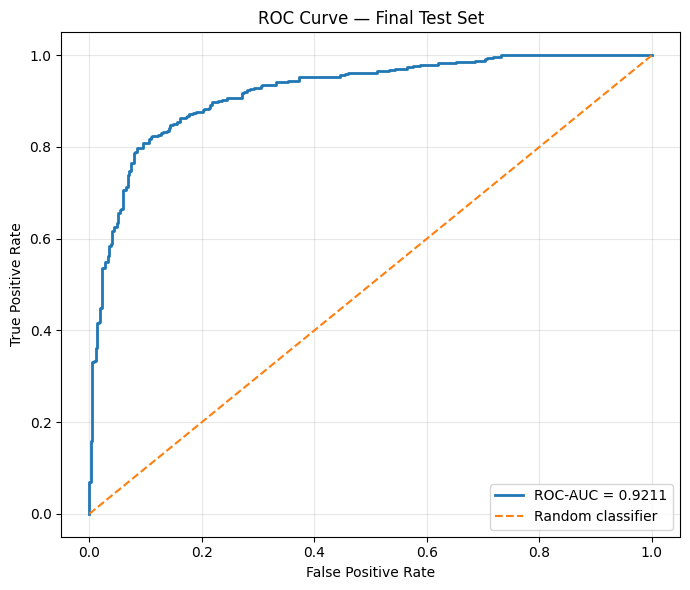

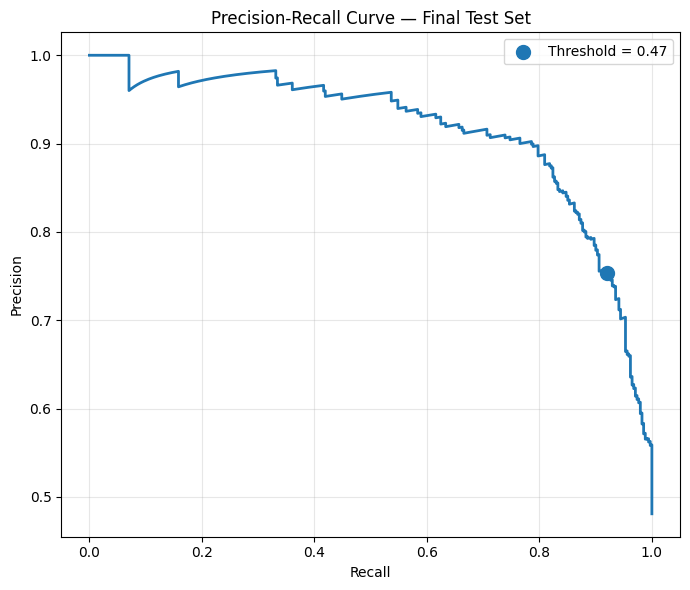

Confusion Matrix:
[[265 103]
 [ 27 314]]


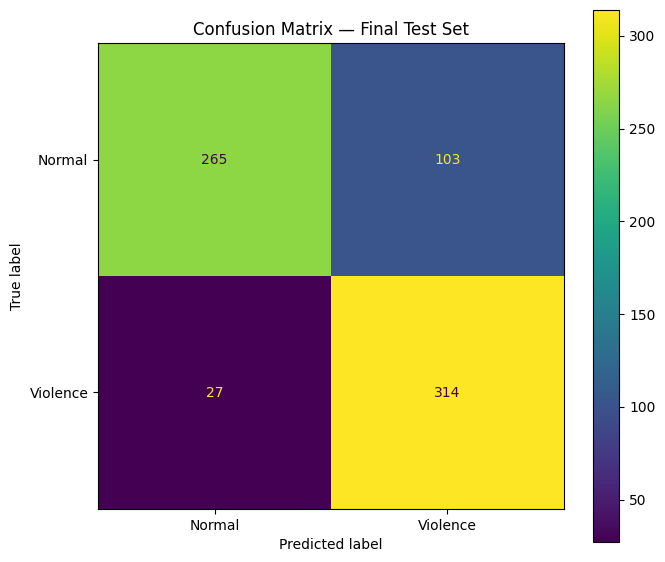


FINAL TEST VISUALIZATION SUMMARY
ROC-AUC             : 0.9211
Locked Threshold    : 0.47
Precision @ 0.47    : 0.7530
Recall @ 0.47       : 0.9208

Confusion Matrix:
[[265 103]
 [ 27 314]]

True Negatives      : 265
False Positives     : 103
False Negatives     : 27
True Positives      : 314


In [127]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ============================================================
# FINAL TEST VISUALIZATIONS
# ============================================================

# ------------------------------------------------------------
# 1. ROC CURVE
# ------------------------------------------------------------

fpr, tpr, roc_thresholds = roc_curve(
    test_targets,
    test_probs
)

roc_auc = roc_auc_score(
    test_targets,
    test_probs
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"ROC-AUC = {roc_auc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Final Test Set")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 2. PRECISION-RECALL CURVE
# ------------------------------------------------------------

precision, recall, pr_thresholds = precision_recall_curve(
    test_targets,
    test_probs
)

plt.figure(figsize=(7, 6))

plt.plot(
    recall,
    precision,
    linewidth=2
)

# Mark our LOCKED threshold = 0.47
locked_threshold = 0.47

locked_preds = (
    test_probs >= locked_threshold
).astype(int)

# Calculate precision and recall specifically at 0.47
from sklearn.metrics import precision_score, recall_score

locked_precision = precision_score(
    test_targets,
    locked_preds,
    zero_division=0
)

locked_recall = recall_score(
    test_targets,
    locked_preds,
    zero_division=0
)

plt.scatter(
    locked_recall,
    locked_precision,
    s=100,
    label=f"Threshold = {locked_threshold}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve — Final Test Set")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 3. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    test_targets,
    test_preds
)

print("Confusion Matrix:")
print(cm)

fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Violence"]
)

disp.plot(
    ax=ax,
    values_format="d",
    colorbar=True
)

ax.set_title(
    "Confusion Matrix — Final Test Set"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 4. PRINT SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("FINAL TEST VISUALIZATION SUMMARY")
print("=" * 55)

print(f"ROC-AUC             : {roc_auc:.4f}")
print(f"Locked Threshold    : {locked_threshold:.2f}")
print(f"Precision @ 0.47    : {locked_precision:.4f}")
print(f"Recall @ 0.47       : {locked_recall:.4f}")

print("\nConfusion Matrix:")
print(cm)

tn, fp, fn, tp = cm.ravel()

print(f"\nTrue Negatives      : {tn}")
print(f"False Positives     : {fp}")
print(f"False Negatives     : {fn}")
print(f"True Positives      : {tp}")

In [131]:
test_dataset = test_feature_loader.dataset

print("Number of tensors:", len(test_dataset.tensors))

for i, tensor in enumerate(test_dataset.tensors):
    print(f"\nTensor {i}:")
    print("Shape:", tensor.shape)
    print("Dtype:", tensor.dtype)

Number of tensors: 2

Tensor 0:
Shape: torch.Size([709, 16, 512])
Dtype: torch.float32

Tensor 1:
Shape: torch.Size([709])
Dtype: torch.float32


In [139]:
# ============================================================
# COMPLETE TEST ERROR ANALYSIS
# ============================================================

import pandas as pd
import numpy as np

# Start from the source-level test dataframe
error_df = test_final.reset_index(drop=True).copy()

# Attach model outputs
error_df["probability"] = test_probs
error_df["prediction"] = test_preds
error_df["actual"] = test_targets

# Human-readable labels
error_df["actual_name"] = error_df["actual"].map({
    0: "Normal",
    1: "Violence"
})

error_df["prediction_name"] = error_df["prediction"].map({
    0: "Normal",
    1: "Violence"
})

# Classify every prediction
error_df["error_type"] = "Correct"

error_df.loc[
    (error_df["actual"] == 0) &
    (error_df["prediction"] == 1),
    "error_type"
] = "False Positive"

error_df.loc[
    (error_df["actual"] == 1) &
    (error_df["prediction"] == 0),
    "error_type"
] = "False Negative"


# ============================================================
# SUMMARY
# ============================================================

print("=" * 60)
print("TEST ERROR ANALYSIS")
print("=" * 60)

print(f"Total samples      : {len(error_df)}")
print(f"Correct predictions: {(error_df['error_type'] == 'Correct').sum()}")
print(f"False positives    : {(error_df['error_type'] == 'False Positive').sum()}")
print(f"False negatives    : {(error_df['error_type'] == 'False Negative').sum()}")


# ============================================================
# FALSE POSITIVES
# ============================================================

false_positives = (
    error_df[
        error_df["error_type"] == "False Positive"
    ]
    .sort_values("probability", ascending=False)
)

print("\n" + "=" * 60)
print("TOP 15 FALSE POSITIVES")
print("=" * 60)

display(
    false_positives[
        [
            "path",
            "class",
            "source_id",
            "probability",
            "actual_name",
            "prediction_name"
        ]
    ].head(15)
)


# ============================================================
# FALSE NEGATIVES
# ============================================================

false_negatives = (
    error_df[
        error_df["error_type"] == "False Negative"
    ]
    .sort_values("probability", ascending=True)
)

print("\n" + "=" * 60)
print("TOP 15 FALSE NEGATIVES")
print("=" * 60)

display(
    false_negatives[
        [
            "path",
            "class",
            "source_id",
            "probability",
            "actual_name",
            "prediction_name"
        ]
    ].head(15)
)


# ============================================================
# SAVE ERROR TABLE
# ============================================================

error_df.to_csv(
    "/kaggle/working/test_error_analysis.csv",
    index=False
)

print("\nSaved:")
print("/kaggle/working/test_error_analysis.csv")

TEST ERROR ANALYSIS
Total samples      : 709
Correct predictions: 579
False positives    : 103
False negatives    : 27

TOP 15 FALSE POSITIVES


,path,class,source_id,probability,actual_name,prediction_name
290,/kaggle/input/datasets/bypktt/xd-violence/trai...,Normal,Normal_Thelma...Louise.1991,0.983195,Normal,Violence
193,/kaggle/input/datasets/bypktt/xd-violence/trai...,Normal,Normal_Deadpool.2.2018,0.977276,Normal,Violence
229,/kaggle/input/datasets/bypktt/xd-violence/trai...,Normal,Normal_v=fnN_FCj-MTA,0.963437,Normal,Violence
200,/kaggle/input/datasets/bypktt/xd-violence/trai...,Normal,Normal_v=rQWPigb7qDY,0.963407,Normal,Violence
167,/kaggle/input/datasets/bypktt/xd-violence/trai...,Normal,Normal_Deadpool.2.2018,0.961032,Normal,Violence
252,/kaggle/input/datasets/bypktt/xd-violence/trai...,Normal,Normal_v=xj64iI5W6r8,0.954081,Normal,Violence
307,/kaggle/input/datasets/bypktt/xd-violence/trai...,Normal,Normal_v=n2lE5MzjmV8,0.953258,Normal,Violence
442,/kaggle/input/datasets/bypktt/xd-violence/trai...,Normal,Normal_v=o4nYn7t1zns,0.948304,Normal,Violence
634,/kaggle/input/datasets/bypktt/xd-violence/test...,Normal,Normal_Thelma...Louise.1991,0.927492,Normal,Violence
187,/kaggle/input/datasets/bypktt/xd-violence/trai...,Normal,Normal_v=BGPGknpq3e0,0.927431,Normal,Violence



TOP 15 FALSE NEGATIVES


,path,class,source_id,probability,actual_name,prediction_name
135,/kaggle/input/datasets/bypktt/xd-violence/trai...,Fighting,Fighting_Bullet.in.the.Head.1990,0.071005,Violence,Normal
115,/kaggle/input/datasets/bypktt/xd-violence/trai...,Fighting,Fighting_v=rldjZyZwUEM,0.079551,Violence,Normal
129,/kaggle/input/datasets/bypktt/xd-violence/trai...,Fighting,Fighting_v=ad1blksyhyM,0.082219,Violence,Normal
704,/kaggle/input/datasets/bypktt/xd-violence/test...,Shooting,Shooting_Operation.Red.Sea.2018,0.084995,Violence,Normal
692,/kaggle/input/datasets/bypktt/xd-violence/test...,Riot,Riot_v=BXR3d22BhHs,0.095154,Violence,Normal
497,/kaggle/input/datasets/bypktt/xd-violence/trai...,Riot,Riot_v=Z1h1h8WmP0E,0.106027,Violence,Normal
102,/kaggle/input/datasets/bypktt/xd-violence/trai...,Explosion,Explosion_v=3wCWpu0HJ_4,0.131950,Violence,Normal
508,/kaggle/input/datasets/bypktt/xd-violence/trai...,Riot,Riot_v=QVDtmAb68KM,0.160814,Violence,Normal
629,/kaggle/input/datasets/bypktt/xd-violence/test...,Fighting,Fighting_v=cuUK-3MNqtw,0.169220,Violence,Normal
122,/kaggle/input/datasets/bypktt/xd-violence/trai...,Fighting,Fighting_v=VHMi-j7W2gM,0.180658,Violence,Normal



Saved:
/kaggle/working/test_error_analysis.csv


In [140]:
from sklearn.metrics import classification_report
import pandas as pd

# Per-class report
report = classification_report(
    test_targets,
    test_preds,
    target_names=["Normal", "Violence"],
    output_dict=True,
    zero_division=0
)

print("Binary performance:")
display(
    pd.DataFrame(report).T
)

Binary performance:


,precision,recall,f1-score,support
Normal,0.907534,0.720109,0.803030,368.000000
Violence,0.752998,0.920821,0.828496,341.000000
accuracy,0.816643,0.816643,0.816643,0.816643
macro avg,0.830266,0.820465,0.815763,709.000000
weighted avg,0.833208,0.816643,0.815278,709.000000


In [141]:
class_results = []

for cls in sorted(test_final["class"].unique()):

    mask = (
        test_final["class"].values == cls
    )

    y_true_cls = test_targets[mask]
    y_pred_cls = test_preds[mask]
    probs_cls = test_probs[mask]

    class_results.append({
        "class": cls,
        "samples": len(y_true_cls),
        "actual_violence": int(y_true_cls.sum()),
        "predicted_violence": int(y_pred_cls.sum()),
        "recall": (
            (y_pred_cls[y_true_cls == 1] == 1).mean()
            if (y_true_cls == 1).sum() > 0
            else np.nan
        )
    })

class_results = pd.DataFrame(class_results)

display(
    class_results.sort_values(
        "recall"
    )
)

,class,samples,actual_violence,predicted_violence,recall
2,Fighting,76,76,64,0.842105
4,Riot,73,73,66,0.904110
1,Explosion,48,48,44,0.916667
5,Shooting,65,65,61,0.938462
0,CarAccident,79,79,79,1.000000
3,Normal,368,0,103,NaN


In [144]:
# Pick a representative false-negative Fighting video

example = error_df[
    (error_df["error_type"] == "False Negative") &
    (error_df["class"] == "Fighting")
].iloc[0]

example_path = example["path"]

print("Selected video:")
print(example_path)

print("\nActual:", example["actual_name"])
print("Model probability:", example["probability"])

Selected video:
/kaggle/input/datasets/bypktt/xd-violence/train/Fighting/Fighting_v=rldjZyZwUEM___1_label_B1-0-0.mp4

Actual: Violence
Model probability: 0.079551004


Sliding-window inference:   0%|          | 0/278 [00:00<?, ?it/s]


Number of windows: 278
Maximum violence probability: 0.7045294046401978
Maximum probability time: 53.67 seconds


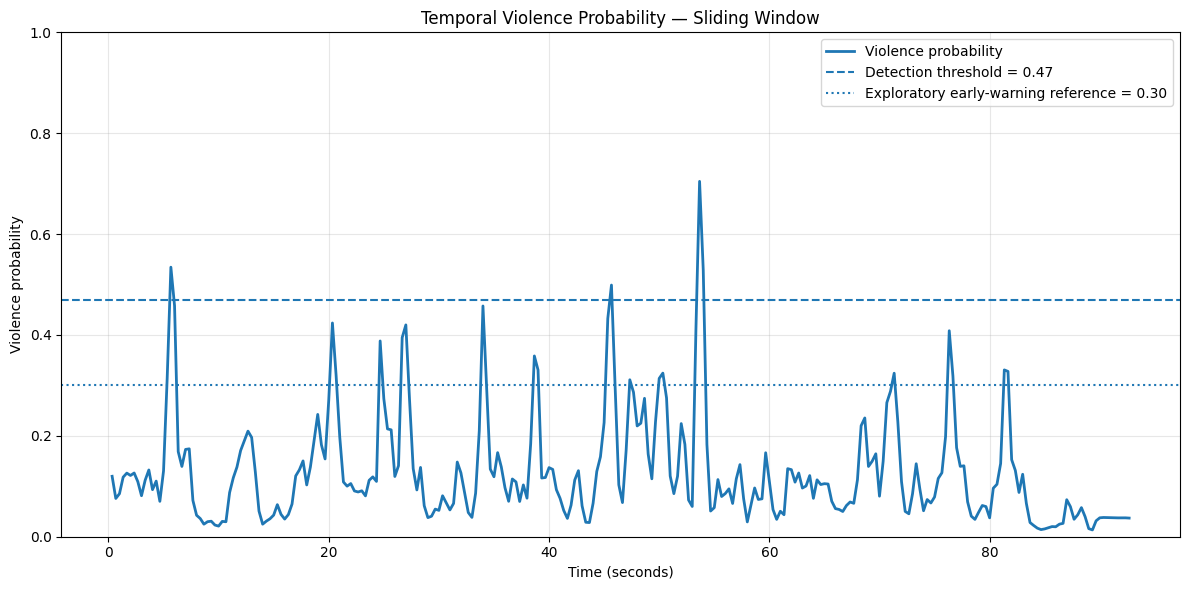

In [146]:
# ============================================================
# SLIDING WINDOW INFERENCE
# ============================================================

window_times = []
window_probs = []

with torch.no_grad():

    for start in tqdm(
        range(
            0,
            len(frames) - NUM_FRAMES + 1,
            STRIDE
        ),
        desc="Sliding-window inference"
    ):

        window = frames[start:start + NUM_FRAMES]

        # [16, 3, 224, 224]
        frame_tensors = torch.stack([
            transform(Image.fromarray(frame))
            for frame in window
        ]).to(device, non_blocking=True)

        # ----------------------------------------------------
        # ResNet18
        # ----------------------------------------------------

        features = feature_extractor(frame_tensors)

        # If ResNet returns [16, 512, 1, 1]
        # convert to [16, 512]
        if features.dim() == 4:
            features = features.squeeze(-1).squeeze(-1)

        # Add batch dimension
        # [16, 512] → [1, 16, 512]
        features = features.unsqueeze(0)

        # ----------------------------------------------------
        # GRU classifier
        # ----------------------------------------------------

        logits = model(features)

        probability = torch.sigmoid(logits).item()

        # Time corresponding to center of window
        center_frame = start + NUM_FRAMES // 2

        center_time = (
            center_frame / fps
            if fps > 0
            else center_frame
        )

        window_times.append(center_time)
        window_probs.append(probability)


window_times = np.array(window_times)
window_probs = np.array(window_probs)

print("\nNumber of windows:", len(window_probs))

print(
    "Maximum violence probability:",
    window_probs.max()
)

max_idx = np.argmax(window_probs)

print(
    "Maximum probability time:",
    f"{window_times[max_idx]:.2f} seconds"
)

# ============================================================
# PLOT
# ============================================================

plt.figure(figsize=(12, 6))

plt.plot(
    window_times,
    window_probs,
    linewidth=2,
    label="Violence probability"
)

plt.axhline(
    0.47,
    linestyle="--",
    linewidth=1.5,
    label="Detection threshold = 0.47"
)

plt.axhline(
    0.30,
    linestyle=":",
    linewidth=1.5,
    label="Exploratory early-warning reference = 0.30"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Violence probability")

plt.title(
    "Temporal Violence Probability — Sliding Window"
)

plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

In [161]:
import numpy as np
import pandas as pd
import torch

model.eval()

val_cached_probs = []
val_cached_targets = []

with torch.no_grad():

    for features, labels in val_feature_loader:

        features = features.to(
            device,
            non_blocking=True
        )

        logits = model(features)

        probs = torch.sigmoid(logits)

        val_cached_probs.extend(
            probs.cpu().numpy()
        )

        val_cached_targets.extend(
            labels.numpy()
        )

val_cached_probs = np.array(
    val_cached_probs
)

val_cached_targets = np.array(
    val_cached_targets
)

print("Probabilities:", val_cached_probs.shape)
print("Targets:", val_cached_targets.shape)

Probabilities: (608,)
Targets: (608,)


In [162]:
val_analysis = val_final.copy().reset_index(drop=True)

val_analysis["probability"] = val_cached_probs

val_analysis["prediction"] = (
    val_cached_probs >= 0.47
).astype(int)

val_analysis["actual_name"] = np.where(
    val_analysis["label"] == 1,
    "Violence",
    "Normal"
)

val_analysis["prediction_name"] = np.where(
    val_analysis["prediction"] == 1,
    "Violence",
    "Normal"
)

val_analysis["error_type"] = "Correct"

val_analysis.loc[
    (val_analysis["label"] == 0) &
    (val_analysis["prediction"] == 1),
    "error_type"
] = "False Positive"

val_analysis.loc[
    (val_analysis["label"] == 1) &
    (val_analysis["prediction"] == 0),
    "error_type"
] = "False Negative"

print(
    val_analysis["error_type"].value_counts()
)

error_type
Correct           506
False Positive     81
False Negative     21
Name: count, dtype: int64


In [163]:
false_positives = val_analysis[
    val_analysis["error_type"] == "False Positive"
].sort_values(
    "probability",
    ascending=False
)

display(
    false_positives[
        [
            "path",
            "class",
            "source_id",
            "probability",
            "actual_name",
            "prediction_name"
        ]
    ].head(15)
)
false_negatives = val_analysis[
    val_analysis["error_type"] == "False Negative"
].sort_values(
    "probability",
    ascending=True
)

display(
    false_negatives[
        [
            "path",
            "class",
            "source_id",
            "probability",
            "actual_name",
            "prediction_name"
        ]
    ].head(15)
)

class_analysis = (
    val_analysis
    .groupby("class")
    .agg(
        samples=("label", "size"),
        mean_probability=("probability", "mean"),
        max_probability=("probability", "max"),
        false_positives=(
            "error_type",
            lambda x: (x == "False Positive").sum()
        ),
        false_negatives=(
            "error_type",
            lambda x: (x == "False Negative").sum()
        )
    )
    .reset_index()
)

display(class_analysis)

,path,class,source_id,probability,actual_name,prediction_name
392,/kaggle/input/datasets/bypktt/xd-violence/trai...,Normal,Normal_Fury.2014,0.986070,Normal,Violence
170,/kaggle/input/datasets/bypktt/xd-violence/trai...,Normal,Normal_Fury.2014,0.976837,Normal,Violence
329,/kaggle/input/datasets/bypktt/xd-violence/trai...,Normal,Normal_v=8teJmzR7Z18,0.976543,Normal,Violence
266,/kaggle/input/datasets/bypktt/xd-violence/trai...,Normal,Normal_v=W0oYXpd_WIU,0.975890,Normal,Violence
227,/kaggle/input/datasets/bypktt/xd-violence/trai...,Normal,Normal_City.of.God.2002,0.970656,Normal,Violence
237,/kaggle/input/datasets/bypktt/xd-violence/trai...,Normal,Normal_The.Notebook.2004,0.969046,Normal,Violence
169,/kaggle/input/datasets/bypktt/xd-violence/trai...,Normal,Normal_v=q6kaZzhD3nY,0.960665,Normal,Violence
375,/kaggle/input/datasets/bypktt/xd-violence/trai...,Normal,Normal_Fury.2014,0.950065,Normal,Violence
282,/kaggle/input/datasets/bypktt/xd-violence/trai...,Normal,Normal_Gladiator.2000,0.946213,Normal,Violence
244,/kaggle/input/datasets/bypktt/xd-violence/trai...,Normal,Normal_v=FOVMrynP_og,0.945660,Normal,Violence


,path,class,source_id,probability,actual_name,prediction_name
112,/kaggle/input/datasets/bypktt/xd-violence/trai...,Fighting,Fighting_New.Kids.Turbo.2010,0.062941,Violence,Normal
592,/kaggle/input/datasets/bypktt/xd-violence/test...,Riot,Riot_v=Y43UkfAe_bc,0.068086,Violence,Normal
66,/kaggle/input/datasets/bypktt/xd-violence/trai...,Explosion,Explosion_v=bEShlfxB1Ik,0.076448,Violence,Normal
122,/kaggle/input/datasets/bypktt/xd-violence/trai...,Fighting,Fighting_Brick.Mansions.2014,0.097027,Violence,Normal
535,/kaggle/input/datasets/bypktt/xd-violence/test...,Fighting,Fighting_New.Kids.Turbo.2010,0.105025,Violence,Normal
497,/kaggle/input/datasets/bypktt/xd-violence/trai...,Shooting,Shooting_Death.Proof.2007,0.105074,Violence,Normal
71,/kaggle/input/datasets/bypktt/xd-violence/trai...,Explosion,Explosion_v=OU0dIK5EJYI,0.122323,Violence,Normal
125,/kaggle/input/datasets/bypktt/xd-violence/trai...,Fighting,Fighting_Fast.Furious.6.2013,0.160352,Violence,Normal
533,/kaggle/input/datasets/bypktt/xd-violence/test...,Fighting,Fighting_New.Kids.Turbo.2010,0.184466,Violence,Normal
456,/kaggle/input/datasets/bypktt/xd-violence/trai...,Riot,Riot_v=IDiqhkK_ucw,0.185754,Violence,Normal


,class,samples,mean_probability,max_probability,false_positives,false_negatives
0,CarAccident,66,0.940091,0.982808,0,0
1,Explosion,53,0.897081,0.991808,0,3
2,Fighting,70,0.677918,0.977356,0,9
3,Normal,309,0.305120,0.986070,81,0
4,Riot,75,0.835843,0.990632,0,5
5,Shooting,35,0.771826,0.976177,0,4


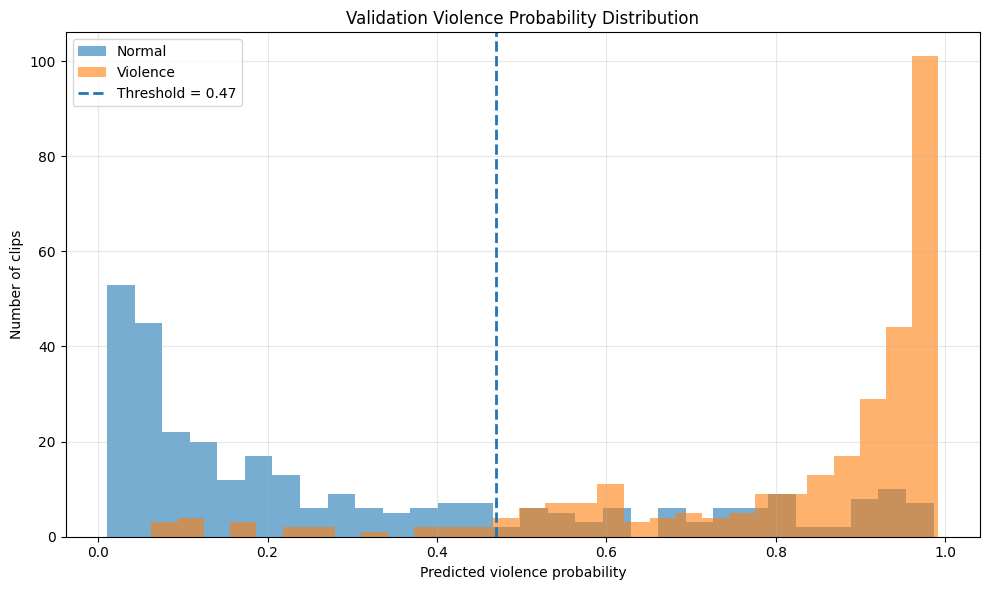

In [164]:
import matplotlib.pyplot as plt

normal_probs = val_analysis[
    val_analysis["label"] == 0
]["probability"]

violence_probs = val_analysis[
    val_analysis["label"] == 1
]["probability"]

plt.figure(figsize=(10, 6))

plt.hist(
    normal_probs,
    bins=30,
    alpha=0.6,
    label="Normal"
)

plt.hist(
    violence_probs,
    bins=30,
    alpha=0.6,
    label="Violence"
)

plt.axvline(
    0.47,
    linestyle="--",
    linewidth=2,
    label="Threshold = 0.47"
)

plt.xlabel("Predicted violence probability")
plt.ylabel("Number of clips")

plt.title(
    "Validation Violence Probability Distribution"
)

plt.legend()
plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()
plt.show()

In [165]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

thresholds = np.arange(
    0.20,
    0.91,
    0.05
)

threshold_results = []

for threshold in thresholds:

    predictions = (
        val_cached_probs >= threshold
    ).astype(int)

    threshold_results.append({
        "threshold": threshold,

        "accuracy": accuracy_score(
            val_cached_targets,
            predictions
        ),

        "precision": precision_score(
            val_cached_targets,
            predictions,
            zero_division=0
        ),

        "recall": recall_score(
            val_cached_targets,
            predictions,
            zero_division=0
        ),

        "f1": f1_score(
            val_cached_targets,
            predictions,
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(
    threshold_results
)

display(threshold_df)

,threshold,accuracy,precision,recall,f1
0,0.20,0.746711,0.667436,0.966555,0.789617
1,0.25,0.773026,0.694915,0.959866,0.806180
2,0.30,0.792763,0.717884,0.953177,0.818966
3,0.35,0.805921,0.733850,0.949833,0.827988
4,0.40,0.815789,0.748011,0.943144,0.834320
5,0.45,0.824013,0.762295,0.933110,0.839098
6,0.50,0.830592,0.778409,0.916388,0.841782
7,0.55,0.825658,0.789790,0.879599,0.832278
8,0.60,0.810855,0.796774,0.826087,0.811166
9,0.65,0.805921,0.802676,0.802676,0.802676


In [207]:
import numpy as np
import torch
from tqdm.auto import tqdm

model.eval()

test_trajectories = []

with torch.no_grad():

    for i in tqdm(
        range(len(test_features)),
        desc="Test temporal trajectories"
    ):

        # One video
        x = test_features[i:i+1].to(device)

        trajectory = []

        # Use progressively more of the 16 temporal positions
        for t in range(1, 17):

            prefix = x[:, :t, :]

            logits = model(prefix)

            probability = torch.sigmoid(logits).item()

            trajectory.append(probability)

        test_trajectories.append(trajectory)


test_trajectories = np.array(test_trajectories)

print("Test trajectories shape:", test_trajectories.shape)

Test temporal trajectories:   0%|          | 0/709 [00:00<?, ?it/s]

Test trajectories shape: (709, 16)


In [208]:
# ============================================================
# STEP 3 — WHEN DOES THE MODEL CROSS THE VIOLENCE THRESHOLD?
# ============================================================

import numpy as np
import pandas as pd

THRESHOLD = 0.47

# test_trajectories shape should be (709, 16)
print("Trajectory shape:", test_trajectories.shape)

# ------------------------------------------------------------
# Find first timestep where probability >= threshold
# ------------------------------------------------------------

crossing_step = []

for trajectory in test_trajectories:

    crossed = np.where(trajectory >= THRESHOLD)[0]

    if len(crossed) == 0:
        crossing_step.append(np.nan)
    else:
        # +1 because Python index 0 = temporal step 1
        crossing_step.append(crossed[0] + 1)

crossing_step = np.array(crossing_step)

# ------------------------------------------------------------
# Build analysis dataframe
# ------------------------------------------------------------

crossing_df = pd.DataFrame({
    "label": test_labels,
    "crossing_step": crossing_step
})

crossing_df["crossing_fraction"] = (
    crossing_df["crossing_step"] / 16
)

crossing_df["crossing_percent"] = (
    crossing_df["crossing_fraction"] * 100
)

# ------------------------------------------------------------
# Overall results
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("OVERALL THRESHOLD CROSSING")
print("=" * 60)

print(
    "Videos crossing threshold:",
    crossing_df["crossing_step"].notna().sum(),
    "/",
    len(crossing_df)
)

print(
    "Videos never crossing:",
    crossing_df["crossing_step"].isna().sum()
)

print("\nCrossing-step distribution:")
print(
    crossing_df["crossing_step"]
    .value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# Violence
# ------------------------------------------------------------

violence_cross = crossing_df[
    crossing_df["label"] == 1
]

print("\n" + "=" * 60)
print("VIOLENCE")
print("=" * 60)

print("Total:", len(violence_cross))

print(
    "Crossed:",
    violence_cross["crossing_step"].notna().sum()
)

print(
    "Never crossed:",
    violence_cross["crossing_step"].isna().sum()
)

print("\nCrossing step statistics:")
print(
    violence_cross["crossing_step"].describe()
)

print("\nCrossing percentage of video:")
print(
    violence_cross["crossing_percent"].describe()
)

# ------------------------------------------------------------
# Normal
# ------------------------------------------------------------

normal_cross = crossing_df[
    crossing_df["label"] == 0
]

print("\n" + "=" * 60)
print("NORMAL")
print("=" * 60)

print("Total:", len(normal_cross))

print(
    "Crossed:",
    normal_cross["crossing_step"].notna().sum()
)

print(
    "Never crossed:",
    normal_cross["crossing_step"].isna().sum()
)

print("\nCrossing step statistics:")
print(
    normal_cross["crossing_step"].describe()
)

print("\nCrossing percentage of video:")
print(
    normal_cross["crossing_percent"].describe()
)

Trajectory shape: (709, 16)

OVERALL THRESHOLD CROSSING
Videos crossing threshold: 542 / 709
Videos never crossing: 167

Crossing-step distribution:
crossing_step
1.0     407
2.0      35
3.0      18
4.0      17
5.0      13
6.0       6
7.0      11
8.0       5
9.0       6
10.0      5
11.0      4
12.0      3
13.0      3
14.0      2
15.0      3
16.0      4
Name: count, dtype: int64

VIOLENCE
Total: 341
Crossed: 327
Never crossed: 14

Crossing step statistics:
count    327.000000
mean       2.067278
std        2.634434
min        1.000000
25%        1.000000
50%        1.000000
75%        2.000000
max       16.000000
Name: crossing_step, dtype: float64

Crossing percentage of video:
count    327.000000
mean      12.920489
std       16.465215
min        6.250000
25%        6.250000
50%        6.250000
75%       12.500000
max      100.000000
Name: crossing_percent, dtype: float64

NORMAL
Total: 368
Crossed: 215
Never crossed: 153

Crossing step statistics:
count    215.000000
mean       2.330

In [209]:
# ============================================================
# STEP 4 — TRAJECTORIES OF STRICTLY ESCALATING VIDEOS
# ============================================================

import numpy as np
import pandas as pd

THRESHOLD = 0.47

# Make sure this is your existing escalation dataframe
df = test_escalation_df.copy()

# Add trajectory index so we know which row belongs to which video
df["trajectory_index"] = np.arange(len(df))

# Select strict escalating violence
esc_violence = df[
    (df["label"] == 1) &
    (df["strict_escalation"] == True)
].copy()

indices = esc_violence["trajectory_index"].astype(int).values

# Extract their full 16-step trajectories
violence_trajectories = test_trajectories[indices]

print("=" * 60)
print("STRICT ESCALATING VIOLENCE TRAJECTORIES")
print("=" * 60)

print("Number of videos:", len(violence_trajectories))
print("Trajectory shape:", violence_trajectories.shape)

# ------------------------------------------------------------
# Mean probability at every temporal step
# ------------------------------------------------------------

mean_trajectory = violence_trajectories.mean(axis=0)
median_trajectory = np.median(violence_trajectories, axis=0)

trajectory_summary = pd.DataFrame({
    "step": np.arange(1, 17),
    "mean_probability": mean_trajectory,
    "median_probability": median_trajectory
})

print("\nMean / median trajectory:")
print(trajectory_summary.to_string(index=False))

# ------------------------------------------------------------
# How many are below threshold at each step?
# ------------------------------------------------------------

below_threshold = (
    violence_trajectories < THRESHOLD
).mean(axis=0) * 100

print("\n" + "=" * 60)
print("PERCENTAGE BELOW THRESHOLD")
print("=" * 60)

for step, pct in enumerate(below_threshold, start=1):
    print(f"Step {step:2d}: {pct:6.2f}%")

# ------------------------------------------------------------
# How many are already above threshold?
# ------------------------------------------------------------

above_threshold = (
    violence_trajectories >= THRESHOLD
).mean(axis=0) * 100

print("\n" + "=" * 60)
print("PERCENTAGE ABOVE THRESHOLD")
print("=" * 60)

for step, pct in enumerate(above_threshold, start=1):
    print(f"Step {step:2d}: {pct:6.2f}%")

STRICT ESCALATING VIOLENCE TRAJECTORIES
Number of videos: 73
Trajectory shape: (73, 16)

Mean / median trajectory:
 step  mean_probability  median_probability
    1          0.401951            0.420099
    2          0.450335            0.409447
    3          0.525999            0.490598
    4          0.597551            0.589351
    5          0.658966            0.693629
    6          0.696897            0.780564
    7          0.734054            0.832279
    8          0.766043            0.859998
    9          0.791008            0.883646
   10          0.816612            0.901800
   11          0.843477            0.921580
   12          0.860055            0.934331
   13          0.871366            0.935954
   14          0.882314            0.944326
   15          0.896127            0.952130
   16          0.911187            0.954484

PERCENTAGE BELOW THRESHOLD
Step  1: 100.00%
Step  2:  65.75%
Step  3:  46.58%
Step  4:  32.88%
Step  5:  24.66%
Step  6:  20.55%
Step  7

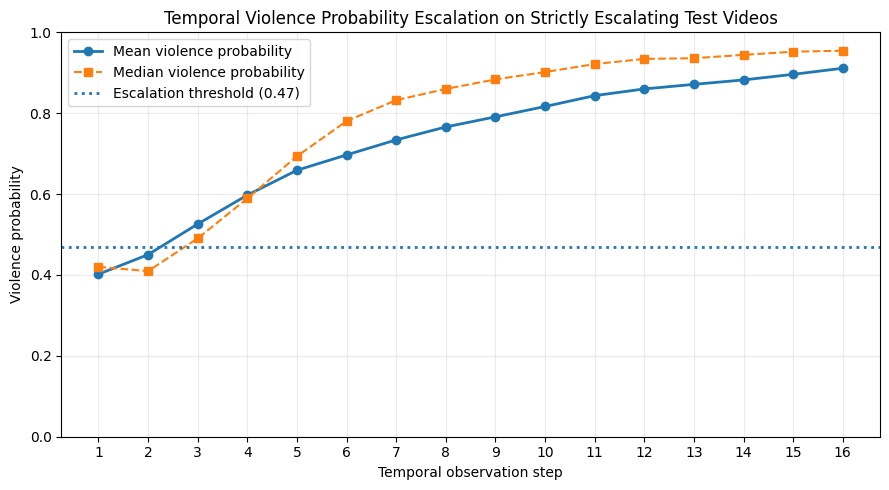

In [210]:
import numpy as np
import matplotlib.pyplot as plt

# Existing trajectories for the 73 strict-escalating violence videos
mean_trajectory = violence_trajectories.mean(axis=0)
median_trajectory = np.median(violence_trajectories, axis=0)

steps = np.arange(1, 17)

plt.figure(figsize=(9, 5))

plt.plot(
    steps,
    mean_trajectory,
    marker="o",
    linewidth=2,
    label="Mean violence probability"
)

plt.plot(
    steps,
    median_trajectory,
    marker="s",
    linestyle="--",
    linewidth=1.5,
    label="Median violence probability"
)

plt.axhline(
    y=0.47,
    linestyle=":",
    linewidth=2,
    label="Escalation threshold (0.47)"
)

plt.xlabel("Temporal observation step")
plt.ylabel("Violence probability")
plt.title(
    "Temporal Violence Probability Escalation "
    "on Strictly Escalating Test Videos"
)

plt.xticks(steps)
plt.ylim(0, 1)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()

plt.savefig(
    "temporal_escalation_test_set.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [211]:
# Find the trajectory closest to the median trajectory
median_trajectory = np.median(
    violence_trajectories,
    axis=0
)

distances = np.mean(
    (violence_trajectories - median_trajectory) ** 2,
    axis=1
)

representative_idx = np.argmin(distances)

original_index = indices[representative_idx]

print("Representative test index:", original_index)

print("\nTrajectory:")
print(
    np.round(
        test_trajectories[original_index],
        4
    )
)

print("\nLabel:")
print(test_escalation_df.iloc[original_index]["label"])

print("\nEarly probability:")
print(test_escalation_df.iloc[original_index]["early_probability"])

print("\nLate probability:")
print(test_escalation_df.iloc[original_index]["late_probability"])

print("\nDelta:")
print(test_escalation_df.iloc[original_index]["probability_delta"])

print("\nSlope:")
print(test_escalation_df.iloc[original_index]["slope"])

Representative test index: 107

Trajectory:
[0.4512 0.4471 0.4536 0.574  0.661  0.7662 0.8469 0.8798 0.9038 0.9218
 0.9234 0.9417 0.9481 0.9593 0.9677 0.9685]

Label:
1.0

Early probability:
0.4512178897857666

Late probability:
0.9684577584266663

Delta:
0.5172398686408997

Slope:
0.03890593525241404
